# ccFBApy reference manual

Cost constrained flux balance analysis (MOMENT, ccFBA) in Python: the reference manual of the Python port of the R package **sybilccFBA** 3.0.2. The manual is made from the R help pages (`R/sybilccFBA/man/*.Rd`). There is one section per help page, plus sections for the Python functions that have no help page. It also has the Python code of the examples, which you can run here.

Run the [setup](#setup) cell first, from the root folder of the repository. The examples of a section can depend on the earlier code cells of the same section, but not on other sections.

*This notebook is generated from `docs/` by `tools/make_reference_notebook.py`; edit the pages in `docs/` and run the script again instead of editing the notebook.*

<a id="contents"></a>

## Contents

- [Setup](#setup)
- **[Introduction](#part-introduction)**
    - [1. Overview](#index)
        - [What the package does](#index--what-the-package-does)
        - [Installation](#index--installation)
        - [Quick start](#index--quick-start)
        - [R help pages and their Python equivalents](#index--r-help-pages-and-their-python-equivalents)
        - [Package information](#index--package-information)
        - [References](#index--references)
    - [2. Inputs, units and conventions](#conventions)
        - [Units](#conventions--units)
        - [Metabolic model (model)](#conventions--metabolic-model-model)
        - [Irreversible model (mod2)](#conventions--irreversible-model-mod2)
        - [Kinetic data (Kcat)](#conventions--kinetic-data-kcat)
        - [Molecular weights (MW)](#conventions--molecular-weights-mw)
        - [Spontaneous reactions (s0001)](#conventions--spontaneous-reactions-s0001)
        - [Protein complex stoichiometry (cpx_stoich)](#conventions--protein-complex-stoichiometry-cpx_stoich)
        - [Budget (RHS) and objective](#conventions--budget-rhs-and-objective)
        - [Gene concentration bounds (geneConcLB, geneConcUB)](#conventions--gene-concentration-bounds-geneconclb-geneconcub)
        - [Solver](#conventions--solver)
        - [verboseMode](#conventions--verbosemode)
        - [Results](#conventions--results)
- **[Functions](#part-functions)**
    - [3. cfba_moment: MOMENT method](#cfba_moment)
        - [Description](#cfba_moment--description)
        - [Usage](#cfba_moment--usage)
        - [Arguments](#cfba_moment--arguments)
        - [Details](#cfba_moment--details)
        - [Value](#cfba_moment--value)
        - [References](#cfba_moment--references)
        - [See also](#cfba_moment--see-also)
        - [Examples](#cfba_moment--examples)
    - [4. cfba_moment_mr: MOMENT with multi-functional enzymes (ccFBA_mr)](#cfba_moment_mr)
        - [Description](#cfba_moment_mr--description)
        - [Usage](#cfba_moment_mr--usage)
        - [Arguments](#cfba_moment_mr--arguments)
        - [Details](#cfba_moment_mr--details)
        - [Value](#cfba_moment_mr--value)
        - [Known issues](#cfba_moment_mr--known-issues)
        - [References](#cfba_moment_mr--references)
        - [See also](#cfba_moment_mr--see-also)
        - [Examples](#cfba_moment_mr--examples)
    - [5. cfba_moment_pw: MOMENT with pairwise OR](#cfba_moment_pw)
        - [Description](#cfba_moment_pw--description)
        - [Usage](#cfba_moment_pw--usage)
        - [Arguments](#cfba_moment_pw--arguments)
        - [Details](#cfba_moment_pw--details)
        - [Value](#cfba_moment_pw--value)
        - [Differences from R](#cfba_moment_pw--differences-from-r)
        - [Check against the MATLAB model](#cfba_moment_pw--check-against-the-matlab-model)
        - [References](#cfba_moment_pw--references)
        - [See also](#cfba_moment_pw--see-also)
        - [Examples](#cfba_moment_pw--examples)
    - [6. getGpr1iso: choose the cheapest isoenzyme](#getGpr1iso)
        - [Description](#getGpr1iso--description)
        - [Usage](#getGpr1iso--usage)
        - [Arguments](#getGpr1iso--arguments)
        - [Details](#getGpr1iso--details)
        - [Value](#getGpr1iso--value)
        - [See also](#getGpr1iso--see-also)
        - [Examples](#getGpr1iso--examples)
    - [7. getccFBA_mat: ccFBA problem as a constraint matrix](#getccFBA_mat)
        - [Description](#getccFBA_mat--description)
        - [Usage](#getccFBA_mat--usage)
        - [Arguments](#getccFBA_mat--arguments)
        - [Details](#getccFBA_mat--details)
        - [Value](#getccFBA_mat--value)
        - [solve_ccFBA_mat](#getccFBA_mat--solve_ccfba_mat)
        - [Differences from R](#getccFBA_mat--differences-from-r)
        - [References](#getccFBA_mat--references)
        - [See also](#getccFBA_mat--see-also)
        - [Examples](#getccFBA_mat--examples)
    - [8. getccFBA_sol: solve the ccFBA problem](#getccFBA_sol)
        - [Description](#getccFBA_sol--description)
        - [Usage](#getccFBA_sol--usage)
        - [Arguments](#getccFBA_sol--arguments)
        - [Value](#getccFBA_sol--value)
        - [flx_MC_tables](#getccFBA_sol--flx_mc_tables)
        - [Details](#getccFBA_sol--details)
        - [References](#getccFBA_sol--references)
        - [See also](#getccFBA_sol--see-also)
        - [Examples](#getccFBA_sol--examples)
    - [9. ccFBA_iso: isoenzymes without getGpr1iso (gene allocation)](#ccFBA_iso)
        - [Description](#ccFBA_iso--description)
        - [The problem](#ccFBA_iso--the-problem)
        - [The formulation](#ccFBA_iso--the-formulation)
        - [Usage](#ccFBA_iso--usage)
        - [Arguments](#ccFBA_iso--arguments)
        - [Value](#ccFBA_iso--value)
        - [Results on iAF1260](#ccFBA_iso--results-on-iaf1260)
        - [See also](#ccFBA_iso--see-also)
        - [Examples](#ccFBA_iso--examples)
    - [10. simulate_EColi: growth of E. coli on several carbon sources](#simulate_EColi)
        - [Description](#simulate_EColi--description)
        - [Usage](#simulate_EColi--usage)
        - [Arguments](#simulate_EColi--arguments)
        - [Details](#simulate_EColi--details)
        - [Value](#simulate_EColi--value)
        - [References](#simulate_EColi--references)
        - [See also](#simulate_EColi--see-also)
        - [Examples](#simulate_EColi--examples)
    - [11. simGeneOverExpr: over expression of one gene](#simGeneOverExpr)
        - [Description](#simGeneOverExpr--description)
        - [Usage](#simGeneOverExpr--usage)
        - [Arguments](#simGeneOverExpr--arguments)
        - [Details](#simGeneOverExpr--details)
        - [Value](#simGeneOverExpr--value)
        - [See also](#simGeneOverExpr--see-also)
        - [Examples](#simGeneOverExpr--examples)
    - [12. mod2irrev: irreversible model](#mod2irrev)
        - [Description](#mod2irrev--description)
        - [Usage](#mod2irrev--usage)
        - [Value / attributes](#mod2irrev--value-attributes)
        - [Details](#mod2irrev--details)
        - [Examples](#mod2irrev--examples)
        - [See also](#mod2irrev--see-also)
    - [13. calc_MW: molecular weights from the genome](#calc_MW)
        - [Description](#calc_MW--description)
        - [Usage](#calc_MW--usage)
        - [Arguments](#calc_MW--arguments)
        - [Details](#calc_MW--details)
        - [Value](#calc_MW--value)
        - [Differences from R](#calc_MW--differences-from-r)
        - [Check against the data sets](#calc_MW--check-against-the-data-sets)
        - [See also](#calc_MW--see-also)
        - [Examples](#calc_MW--examples)
    - [14. readmodel: read the MOMENT model of MATLAB](#readmodel)
        - [Description](#readmodel--description)
        - [Usage](#readmodel--usage)
        - [Arguments](#readmodel--arguments)
        - [Details](#readmodel--details)
        - [Value](#readmodel--value)
        - [Differences from R](#readmodel--differences-from-r)
        - [References](#readmodel--references)
        - [See also](#readmodel--see-also)
        - [Examples](#readmodel--examples)
    - [15. addGlcTrns: glucose transport constraint](#addGlcTrns)
        - [Description](#addGlcTrns--description)
        - [Usage](#addGlcTrns--usage)
        - [Arguments](#addGlcTrns--arguments)
        - [Details](#addGlcTrns--details)
        - [Value](#addGlcTrns--value)
        - [See also](#addGlcTrns--see-also)
        - [Examples](#addGlcTrns--examples)
    - [16. Utilities](#utilities)
        - [The R data sets (no rdata needed)](#utilities--the-r-data-sets-no-rdata-needed)
        - [scatterPlot](#utilities--scatterplot)
        - [remove_enzyme_layer](#utilities--remove_enzyme_layer)
- **[R only (replaced or not needed)](#part-r-only-replaced-or-not-needed)**
    - [17. getRevFlux: fluxes of the reversible model](#getRevFlux)
        - [Description](#getRevFlux--description)
        - [Usage (R)](#getRevFlux--usage-r)
        - [Value](#getRevFlux--value)
        - [Python equivalent](#getRevFlux--python-equivalent)
        - [See also](#getRevFlux--see-also)
    - [18. sysBiolAlg_ccFBA: problem object of ccFBA](#sysBiolAlg_ccFBA)
        - [Description (R)](#sysBiolAlg_ccFBA--description-r)
        - [initialize method](#sysBiolAlg_ccFBA--initialize-method)
        - [Details](#sysBiolAlg_ccFBA--details)
        - [Example](#sysBiolAlg_ccFBA--example)
        - [References](#sysBiolAlg_ccFBA--references)
- **[Data](#part-data)**
    - [19. Data sets](#data)
        - [Two versions of the models](#data--two-versions-of-the-models)
        - [iAF1260](#data--iaf1260)
        - [iJO1366](#data--ijo1366)
        - [iML1515](#data--iml1515)
        - [iMM904](#data--imm904)
        - [kcat](#data--kcat)
        - [mw](#data--mw)
        - [mw_iML1515](#data--mw_iml1515)
        - [yst_kcat](#data--yst_kcat)
        - [yst_mw](#data--yst_mw)
        - [Data sets in the package](#data--data-sets-in-the-package)
        - [How the data sets were made](#data--how-the-data-sets-were-made)
        - [Other data files](#data--other-data-files)
- **[Differences](#part-differences)**
    - [20. Differences from R and known issues](#differences)
        - [General](#differences--general)
        - [Per function](#differences--per-function)
        - [Known issues](#differences--known-issues)
        - [Errors in the R help pages](#differences--errors-in-the-r-help-pages)

<a id="setup"></a>

## Setup

Imports and options used by all the examples.

In [1]:
# Setup: run this cell first, from the root folder of the repository (the examples read models/ and data/).
import os
import sys
import warnings

if not os.path.isdir('models') or not os.path.isdir('data'):
    raise RuntimeError('Start the notebook from the root folder of the repository (current folder: %s)' % os.getcwd())
if os.path.isdir('ccfbapy'):            # use the package of the repository (not installed)
    sys.path.insert(0, os.getcwd())
import ccfbapy                          # pip install ccFBApy, or the folder ccfbapy of the repository
print('ccfbapy', ccfbapy.__version__, 'from', os.path.dirname(ccfbapy.__file__))
warnings.filterwarnings('ignore')

import pandas as pd
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 12)
%matplotlib inline

ccfbapy 0.1.0 from /workspace/ccFBA3/ccfbapy


[↑ Back to contents](#contents)

<a id="part-introduction"></a>

# Introduction

<a id="index"></a>

## 1. Overview

Cost constrained flux balance analysis (ccFBA) in Python. This is a port of the R package
**sybilccFBA** (version 3.0.2, by Abdelmoneim Amer Desouki). It is built on
[COBRApy](https://github.com/opencobra/cobrapy) and [optlang](https://github.com/opencobra/optlang)
instead of [sybil](https://CRAN.R-project.org/package=sybil).

This manual is based on the R help pages in `R/sybilccFBA/man/*.Rd`. Each R help page has a section here that
describes the Python function, or says what replaces it. Each section
also gives the R usage for comparison.

<a id="index--what-the-package-does"></a>

### What the package does

Flux balance analysis (FBA) finds the fluxes of a metabolic model at steady state (Orth, Thiele &
Palsson 2010). Cost constrained FBA also limits the fluxes by the amount of enzyme the cell can afford.
It needs three inputs besides the model:

- kinetic data: the turnover number `kcat` of the enzyme of each reaction,
- the molecular weight (MW) of each protein,
- the gene-protein-reaction (GPR) rules of the model.

Two constraints are added to FBA:

```
v_i <= kcat_i * g_i        # flux <= turnover number x enzyme concentration
sum_g (MW_g * g_g) <= C    # total enzyme mass <= budget C (0.27 g/gDW for E. coli)
```

The package implements:

1. **MOMENT** (MetabOlic Modeling with ENzyme kineTics), Adadi et al. (2012):
   [`cfba_moment`](#cfba_moment), and [`cfba_moment_pw`](#cfba_moment_pw) written like the
   original MATLAB implementation.
2. **ccFBA**, an improvement of MOMENT (Desouki 2016):
    - multi-functional enzymes: an enzyme that catalyzes several reactions must share its
      concentration between them ([`ccFBA_mr`](#cfba_moment_mr));
    - only the cheapest isoenzyme of each reaction is used
      ([`getGpr1iso`](#getGpr1iso));
    - optional protein complex stoichiometry
      ([`getccFBA_mat`](#getccFBA_mat), [`getccFBA_sol`](#getccFBA_sol));
    - new in Python: [`ccFBA_iso`](#ccFBA_iso) keeps all the isoenzymes and allocates each gene
      to the complexes that use it, instead of choosing one isoenzyme with `getGpr1iso`.


[↑ Back to contents](#contents)

<a id="index--installation"></a>

### Installation

```
pip install ccFBApy              # the package (imported as ccfbapy), with the data sets of sybilccFBA
pip install "ccFBApy[all]"       # + matplotlib for scatterPlot
```

From a copy of the repository: `pip install .` (or `pip install -e ".[all,test]"` for development; run the
tests with `pytest`). Without installing, run Python from the root folder of the repository, where the
folder `ccfbapy` is.

The examples of this manual read the SBML models of `models/` and the tables of `data/`, or the data sets
shipped with the package ([`ccfbapy.datasets`](#data--data-sets-in-the-package): SBML and CSV files). Run
them from the root folder of the repository.


[↑ Back to contents](#contents)

<a id="index--quick-start"></a>

### Quick start

In [2]:
import cobra
import pandas as pd
from ccfbapy import cfba_moment

model = cobra.io.read_sbml_model('models/iAF1260.xml')   # run from the root folder of the repository
mw = pd.read_csv('data/Ecoli_MW.csv')      # gene, molecular weight (g/mmol)
kcat = pd.read_csv('data/Ecoli_kcat.csv')  # rxn_id, val (1/s), dirxn

res = cfba_moment(model, kcat, MW=mw, RHS=0.27, medval=3600*22.6, verboseMode=1)
print(res['status'], res['obj'])           # optimal 0.4552...
print(res['rxnFlx']['EX_glc__D_e'])        # net flux of glucose exchange

Preparing LP ...


Adding variables...
Adding constraints...


Solving LP ...


optimal 0.45526727235223396
-8.0


See [Inputs, units and conventions](#conventions) for the formats of `Kcat`, `MW` and `cpx_stoich`,
and [Differences from R and known issues](#differences) before you port R code.


[↑ Back to contents](#contents)

<a id="index--r-help-pages-and-their-python-equivalents"></a>

### R help pages and their Python equivalents

| R help page (`man/*.Rd`) | Python | Status |
|---|---|---|
| `sybilccFBA-package.Rd` | this page | |
| [`cfba_moment.Rd`](#cfba_moment) | `ccfbapy.cfba_moment()` | ported |
| [`cfba_moment_mr.Rd`](#cfba_moment_mr) | `ccfbapy.ccFBA_mr()` | ported (no FVA) |
| [`cfba_moment_pw.Rd`](#cfba_moment_pw) | `ccfbapy.cfba_moment_pw()` | ported |
| [`getGpr1iso.Rd`](#getGpr1iso) | `ccfbapy.getGpr1iso()` | ported |
| [`getccFBA_mat.Rd`](#getccFBA_mat) | `ccfbapy.getccFBA_mat()`, `solve_ccFBA_mat()` | ported |
| [`getccFBA_sol.Rd`](#getccFBA_sol) | `ccfbapy.getccFBA_sol()` | ported |
| [`getRevFlux.Rd`](#getRevFlux) | `IrrevModel.net_flux()`, `rxnFlx` in the results | not needed |
| [`simulate_EColi.Rd`](#simulate_EColi) | `ccfbapy.simulate_EColi()` | ported |
| [`sysBiolAlg_ccFBA-class.Rd`](#sysBiolAlg_ccFBA) | `solve_ccFBA_mat()` | replaced |
| [`initialize-methods.Rd`](#sysBiolAlg_ccFBA--initialize-method) | `solve_ccFBA_mat()` | replaced |
| [`calc_MW.Rd`](#calc_MW) | `ccfbapy.calc_MW()` | ported |
| [`readmodel.Rd`](#readmodel) | `ccfbapy.readmodel()`, `read_moment_files()` | ported |
| [`addGlcTrns.Rd`](#addGlcTrns) | `ccfbapy.addGlcTrns()` | ported (completed) |
| [`iAF1260.Rd`](#data--iaf1260), [`iJO1366.Rd`](#data--ijo1366), [`iML1515.Rd`](#data--iml1515), [`iMM904.Rd`](#data--imm904) | `datasets.load_model()` (SBML), `models/*.xml` | available |
| [`kcat.Rd`](#data--kcat), [`mw.Rd`](#data--mw), [`mw_iML1515.Rd`](#data--mw_iml1515) | `datasets.load_dataset()` (CSV), `data/*.csv` | available |
| [`yst_kcat.Rd`](#data--yst_kcat), [`yst_mw.Rd`](#data--yst_mw) | `datasets.load_dataset()` (CSV), `data/yeast_*.csv` | available |

Python functions that have no R help page:

| Python | Page |
|---|---|
| `ccfbapy.mod2irrev()`, class `IrrevModel` (sybil's `mod2irrev`) | [mod2irrev](#mod2irrev) |
| `ccfbapy.solve_ccFBA_mat()` | [getccFBA_mat](#getccFBA_mat--solve_ccfba_mat) |
| `ccfbapy.flx_MC_tables()` | [getccFBA_sol](#getccFBA_sol--flx_mc_tables) |
| `ccfbapy.ccFBA_iso()`, `getccFBA_iso_mat()`: isoenzymes without `getGpr1iso` (gene allocation) | [ccFBA_iso](#ccFBA_iso) |
| `ccfbapy.simGeneOverExpr()` (R source `R/OverExpr/simGeneOverExpr.R`) | [simGeneOverExpr](#simGeneOverExpr) |
| `ccfbapy.datasets`: the data sets of sybilccFBA as SBML and CSV | [Data sets](#data--data-sets-in-the-package) |
| `ccfbapy.scatterPlot()`, `ccfbapy.remove_enzyme_layer()` | [Utilities](#utilities) |


[↑ Back to contents](#contents)

<a id="index--package-information"></a>

### Package information

| | |
|---|---|
| R package | sybilccFBA 3.0.2 (2022-08-13) |
| Title | Cost Constrained Flux Balance Analysis (ccFBA): MetabOlic Modeling with ENzyme kineTics (MOMENT) |
| Author | Abdelmoneim Amer Desouki |
| License | GPL-3 |
| Python package | `ccFBApy` on PyPI, imported as `ccfbapy` |
| Python dependencies | cobra, optlang, pandas, numpy, scipy; optional matplotlib |

The R help page `sybilccFBA-package.Rd` still gives version 0.0.1 (2013-06-03); `DESCRIPTION` and
`NEWS` give 3.0.2.


[↑ Back to contents](#contents)

<a id="index--references"></a>

### References

- Adadi R, Volkmer B, Milo R, Heinemann M, Shlomi T (2012). Prediction of microbial growth rate
  versus biomass yield by a metabolic network with kinetic parameters. *PLoS Comput Biol* 8(7):
  e1002575. [doi:10.1371/journal.pcbi.1002575](https://doi.org/10.1371/journal.pcbi.1002575)
- Desouki AA (2016). *Algorithms for improving the predictive power of flux balance analysis.*
  PhD dissertation.
- Gelius-Dietrich G, Desouki AA, Fritzemeier CJ, Lercher MJ (2013). sybil – Efficient
  constraint-based modelling in R. *BMC Systems Biology* 7: 125.
- Orth JD, Thiele I, Palsson BØ (2010). What is flux balance analysis? *Nat Biotechnol* 28:
  245–248.


[↑ Back to contents](#contents)

<a id="conventions"></a>

## 2. Inputs, units and conventions

The R help pages describe the same arguments (`model`, `mod2`, `Kcat`, `MW`, `RHS`, `medval`,
`cpx_stoich`, ...) on every page. This page describes their Python formats once. The function
pages link here.

<a id="conventions--units"></a>

### Units

| Quantity | Symbol | Unit |
|---|---|---|
| flux | `v` | mmol/gDW/h |
| turnover number, input | `kcat` | 1/s (converted to 1/h inside the functions: × 3600) |
| turnover number for missing values | `medval` | **1/h** (not converted, e.g. `3600*22.6`) |
| enzyme (gene) concentration | `g` | mmol/gDW |
| molecular weight | `MW` | g/mmol (= kDa), e.g. 89.12 for b0002 |
| budget of metabolic protein | `C`, `RHS` | g protein/gDW (0.27 for *E. coli*) |
| protein cost (molecular crowding) | `MC = MW * g` | g protein/gDW |

The R help pages give the unit of `MW` as g/mol. The values in the data sets (`mw`,
`mw_iML1515`, `yst_mw`, `data/*MW.csv`) are in g/mmol (kDa), which is what the budget
constraint needs (`MW * g` in g/gDW). [`calc_MW`](#calc_MW) returns g/mol,
so divide its output by 1000: `pd.DataFrame({'gene': geneCnt['Synonym'], 'mw': geneCnt['mw'] / 1000})`.


[↑ Back to contents](#contents)

<a id="conventions--metabolic-model-model"></a>

### Metabolic model (`model`)

A `cobra.Model`. There are two ways to get the models used in the examples:

| Source | Reaction ids | Example |
|---|---|---|
| `datasets.load_model('iAF1260')` (the R data set `iAF1260`) | as in sybil | `R_EX_glc_e_`, `R_ATPM` |
| `datasets.load_model('iML1515')` (the R data set `iML1515`) | as in sybil | `EX_glc__D(e)`, `ATPM` |
| `cobra.io.read_sbml_model('models/iAF1260.xml')` or `datasets.load_model('iAF1260', source='bigg')` | BiGG ids, no `R_` prefix | `EX_glc__D_e`, `ATPM` |

`datasets` is `ccfbapy.datasets`. The models are SBML files; see [Data sets](#data) and
[Two versions of the models](#data--two-versions-of-the-models).

A reaction is treated as reversible when its `lower_bound < 0`.


[↑ Back to contents](#contents)

<a id="conventions--irreversible-model-mod2"></a>

### Irreversible model (`mod2`)

In R, `mod2` is the irreversible model of `model` (sybil's `mod2irrev`). In Python:

- `cfba_moment` and `ccFBA_mr` have **no** `mod2` argument. They work on a copy of the cobra model
  and use its bounds. A reversible reaction gets one kcat constraint on its forward variable and one
  on its reverse variable.
- `getccFBA_mat`, `getccFBA_sol`, `simulate_EColi` and `simGeneOverExpr` (with `getccFBA_sol`) use
  an [`IrrevModel`](#mod2irrev) made by `mod2irrev(model)`. Reversible reactions are
  split in `<id>_f` and `<id>_b`. The bounds of the fluxes are taken from `mod2.lowbnd` and
  `mod2.uppbnd`, so you can change them there before solving, as in R.


[↑ Back to contents](#contents)

<a id="conventions--kinetic-data-kcat"></a>

### Kinetic data (`Kcat`)

A `pandas.DataFrame` with one row per reaction and direction:

| Column | Content |
|---|---|
| `rxn_id` | reaction id |
| `val` | kcat in 1/s |
| `dirxn` | `1` forward, `-1` reverse direction |
| `src` | optional: source of the value (used in `getccFBA_mat` outputs, `kcat_src_ir`) |

Reactions without a value for a direction use `medval` (in 1/h). The default is the median of `val`
(after conversion to 1/h).

The functions read the table in different ways:

| Function | Column lookup | Matching of `rxn_id` |
|---|---|---|
| `cfba_moment`, `ccFBA_mr` | `val` must be the **second** column (it is converted by position) | `rxn_id` must be `'R_' + reaction id`. The prefix is added to the reaction id unless it already starts with `R_` |
| `getccFBA_mat`, `getccFBA_sol`, `simulate_EColi` | by name | reaction id with or without the `R_` prefix |

`data/Ecoli_kcat.csv` and the R data set `kcat` already have the `R_` prefix. The kcat table
`allKcats_upd34_dd_h.csv` (column `ijo_id`) does not. To use it with `cfba_moment` or
`ccFBA_mr`, add the prefix: `kcat['rxn_id'] = 'R_' + kcat['rxn_id']`. Otherwise all
reactions silently get `medval`.


[↑ Back to contents](#contents)

<a id="conventions--molecular-weights-mw"></a>

### Molecular weights (`MW`)

A `pandas.DataFrame`. The **first column** is the gene id and the **second column** is the molecular
weight in g/mmol. Column names do not matter (`Synonym`/`mw`, `gene`/`mw`, ...). If a gene appears
more than once, the first row is used.

Genes without a molecular weight get no cost: they are left out of the budget constraint.


[↑ Back to contents](#contents)

<a id="conventions--spontaneous-reactions-s0001"></a>

### Spontaneous reactions (`s0001`)

*E. coli* models use the pseudo gene `s0001` for spontaneous reactions. It has no molecular weight
in `mw`.

- `cfba_moment`, `ccFBA_mr`: reactions whose whole GPR is `s0001` are not constrained. Other
  reactions that contain `s0001` (e.g. `b0875 or s0001`) use a variable `g_s0001` that has no
  cost, so in practice these reactions are free. The R version removes `s0001` from these rules
  (e.g. `b0875 or s0001` becomes `b0875`) for the rule strings it knows. The Python version
  has the same list, but cobra writes the rules without parentheses (`b0875 or s0001`), so
  they do not match and are not changed.
- `cfba_moment_pw`: `s0001` is removed from the OR rules (e.g. `b0875 or s0001` becomes `b0875`),
  as R does.
- `getccFBA_mat`: `getGpr1iso` prefers terms with unknown MW, so `s0001` is chosen for
  `b0875 or s0001` and the reaction has no cost (as in R).
- `ccFBA_iso`: `s0001` is a gene without MW (no cost), unless it is removed with `rm_genes=['s0001']`.
- The R examples add `s0001` with a very small MW (0.001) to the MW table.


[↑ Back to contents](#contents)

<a id="conventions--protein-complex-stoichiometry-cpx_stoich"></a>

### Protein complex stoichiometry (`cpx_stoich`)

Optional `pandas.DataFrame` with at least the columns:

| Column | Content |
|---|---|
| `genes` | comma separated gene ids of the complex, **sorted**, e.g. `b2221,b2222` |
| `stoich` | comma separated number of subunits of each gene, same order, e.g. `2,2` |

Complexes that are not found in the table get one subunit per gene. An example is
`R/sybilccFBA/inst/extdata/cpx_stoich_me.csv`.


[↑ Back to contents](#contents)

<a id="conventions--budget-rhs-and-objective"></a>

### Budget (`RHS`) and objective

- `RHS` is the budget `C`: `sum(MW_g * g_g) <= RHS`.
- `cfba_moment`, `ccFBA_mr`: when `RHS` is `None` no budget constraint is added and `objVal`
  is ignored, so the result is an FBA with the kcat constraints only.
- `getccFBA_mat`: when `RHS` is `None` the problem is to minimize the budget needed to reach the
  objective value `objVal` (default: the FBA optimum).


[↑ Back to contents](#contents)

<a id="conventions--gene-concentration-bounds-geneconclb-geneconcub"></a>

### Gene concentration bounds (`geneConcLB`, `geneConcUB`)

Lower and upper bounds of the gene concentrations, in mmol/gDW. The defaults are 0 and 1000. You
can give a `dict` `{gene_id: value}` to all functions. `getccFBA_mat` and `getccFBA_sol` also
accept a list in the order of `model.genes`. For example, you can simulate over expression with a
lower bound (see [`simGeneOverExpr`](#simGeneOverExpr)).


[↑ Back to contents](#contents)

<a id="conventions--solver"></a>

### Solver

The R functions have a `solver` argument (`glpkAPI`, `cplexAPI`, ...). In Python the argument is
accepted but **not used**:

- `cfba_moment` and `ccFBA_mr` use the solver of the model (`model.solver`). To change it:
  `model.solver = 'glpk'`.
- `getccFBA_mat` / `solve_ccFBA_mat` use cobra's default solver
  (`cobra.Configuration().solver`), or the `interface` argument of `solve_ccFBA_mat`.


[↑ Back to contents](#contents)

<a id="conventions--verbosemode"></a>

### `verboseMode`

`0` prints almost nothing, `1` prints status messages, `2` prints more detail, `>2` prints the
processing of each reaction (`cfba_moment`, `ccFBA_mr`). The R option `3` also writes the LP
problem to a file. There is no such option in Python. Use the optlang problem instead, e.g.
`open('prob.lp', 'w').write(res['prob'].to_lp())` (GLPK interface).


[↑ Back to contents](#contents)

<a id="conventions--results"></a>

### Results

All functions return a `dict`. The ccFBA functions share these keys:

| Key | Content |
|---|---|
| `obj` | objective value (e.g. growth rate, 1/h) |
| `status` | solver status, `'optimal'` when solved |
| `rxnFlx` | `dict` reaction id → net flux (forward − reverse) of the reactions of `model` |
| `geneConc` | `dict` gene id → concentration (mmol/gDW) |
| `prob` | the optlang problem |

The R functions return sybil objects (`sol`, `prob`, `geneCol`). Row and column indices
in the Python results are **0-based**, while they are 1-based in R.


[↑ Back to contents](#contents)

<a id="part-functions"></a>

# Functions

<a id="cfba_moment"></a>

## 3. cfba_moment: MOMENT method

*R help page: `man/cfba_moment.Rd`. Python: `ccfbapy/cfba_moment.py`, function `cfba_moment()`.*

<a id="cfba_moment--description"></a>

### Description

Uses the GPR rules, kcat values and molecular weights to compute fluxes with the MOMENT method
(Adadi et al. 2012). Each reaction with a GPR gets a kcat constraint on its flux. The total
mass of the enzymes is limited by the budget `RHS`. The objective of the model (e.g. growth) is
maximized.


[↑ Back to contents](#contents)

<a id="cfba_moment--usage"></a>

### Usage

```python
from ccfbapy import cfba_moment

cfba_moment(model, Kcat=None, MW=None, selected_rxns=None, verboseMode=2, objVal=None,
            RHS=None, solver="GLPK", medval=None, geneConcLB=None, geneConcUB=None)
```

R:

```r
cfba_moment(model, mod2=NULL, Kcat, MW=NULL, selected_rxns=NULL, verboseMode=2, objVal=NULL,
            RHS=NULL, solver=SYBIL_SETTINGS("SOLVER"), medval=NULL, runFVA=FALSE, fvaRxn=NULL,
            geneConcLB=rep(0,length(allGenes(model))), geneConcUB=rep(1000,length(allGenes(model))))
```


[↑ Back to contents](#contents)

<a id="cfba_moment--arguments"></a>

### Arguments

| Argument | Description |
|---|---|
| `model` | `cobra.Model`. It is copied, so the input model is not changed. The bounds of its reactions are used. |
| `Kcat` | kcat values in 1/s: DataFrame `rxn_id`, `val`, `dirxn`. `val` must be the second column and `rxn_id` must have the `R_` prefix, see [Kcat](#conventions--kinetic-data-kcat). |
| `MW` | molecular weights in g/mmol: DataFrame, first column gene, second column MW. See [MW](#conventions--molecular-weights-mw). |
| `selected_rxns` | list of reaction ids to constrain. Default: all reactions with a GPR, except those whose GPR is only `s0001`. |
| `verboseMode` | amount of output: `0` almost nothing, `1` status messages, `>2` each reaction. Default `2`. |
| `objVal` | accepted for compatibility with R, **not used** (see Details). |
| `RHS` | the budget C in g/gDW, 0.27 for *E. coli*. When `None` no budget constraint is added. |
| `solver` | accepted for compatibility with R, not used. The solver of `model` is used. |
| `medval` | kcat in **1/h** for reactions without a kcat, e.g. `3600*22.6`. Default: median of `Kcat['val']` (in 1/h). |
| `geneConcLB` | `dict` gene id → lower bound of the gene concentration (mmol/gDW). Default 0. |
| `geneConcUB` | `dict` gene id → upper bound of the gene concentration. Default 1000. |

The R arguments `mod2`, `runFVA` and `fvaRxn` are not available.


[↑ Back to contents](#contents)

<a id="cfba_moment--details"></a>

### Details

Main steps:

1. Add a concentration variable `g_<gene>` for every gene of the model.
2. For each selected reaction, parse the GPR rule.
3. Add variables and constraints according to the rule (table below).
4. Add the budget ("solvent capacity") constraint `MW`: `sum(MW_g * g_g) <= RHS`, for the genes
   that have a molecular weight.

Variables and constraints for each type of GPR rule:

| GPR rule | Variables | Constraints |
|---|---|---|
| one gene `A` | | `<rxn>_kcat`: `v <= kcat * g_A` |
| complex `A and B` | `cpx_<rxn>` | `<rxn>_kcat`: `v <= kcat * cpx`; `<rxn>_A`: `cpx <= g_A`; `<rxn>_B`: `cpx <= g_B` |
| isoenzymes `A or B` | | `<rxn>`: `v <= kcat * (g_A + g_B)` |
| `(A and B) or C` | `cpx_<rxn>_<p>` for AND term `p` (0-based) | `<rxn>`: `v <= kcat * (cpx_<rxn>_0 + g_C)`; `Aux_<n>`: `cpx <= g` for each gene of the term |

A reversible reaction (lower bound < 0) gets the same constraint for its reverse variable,
with the reverse kcat (`dirxn = -1`): `<rxn>_b_kcat` or `<rxn>_b`.

An OR with more than two terms is written as one constraint, not pairwise as in the original
MATLAB implementation of MOMENT (see [`cfba_moment_pw`](#cfba_moment_pw), which also works on the
irreversible model and removes `s0001` from the rules).

The constraints are added to the solver problem of a copy of `model`. They are not added as
cobra reactions. If the copy already has an enzyme layer from an earlier call, it is removed first
(see [`remove_enzyme_layer`](#utilities--remove_enzyme_layer)).

In R, when `RHS` is `NULL` the problem becomes: find the minimum budget that gives `objVal`
(default: FBA optimum). The Python version does not implement this. With `RHS=None` it
solves FBA with the kcat constraints only. Use [`getccFBA_mat`](#getccFBA_mat) with
`RHS=None` for the minimum budget.


[↑ Back to contents](#contents)

<a id="cfba_moment--value"></a>

### Value

A `dict`:

| Key | Content |
|---|---|
| `obj` | objective value (growth rate, 1/h) |
| `status` | solver status (`'optimal'`) |
| `rxnFlx` | `dict` reaction id → net flux (forward − reverse) |
| `geneConc` | `dict` gene id → concentration (mmol/gDW), all genes of the model |
| `rxnkcatRow` | DataFrame, one row per kcat term: `rsn` (reaction index), `rxn_id`, `dirxn`, `rowind` (position of the constraint in `prob.constraints`; `None` for OR rules), `colind` (position of the enzyme variable in `prob.variables`), `val` (kcat, 1/h) |
| `prob` | the optlang problem (`model.solver` of the copy) |
| `model` | the copy of `model` that has the enzyme layer |

R returns `sol` (sybil `optsol`), `prob` (`sysBiolAlg`), `geneCol` (gene → column) and, since
version 3.0.2, `geneConc`.


[↑ Back to contents](#contents)

<a id="cfba_moment--references"></a>

### References

Adadi R, Volkmer B, Milo R, Heinemann M, Shlomi T (2012). Prediction of microbial growth rate versus
biomass yield by a metabolic network with kinetic parameters. *PLoS Comput Biol* 8(7).
doi:10.1371/journal.pcbi.1002575

Gelius-Dietrich G, Desouki AA, Fritzemeier CJ, Lercher MJ (2013). sybil – Efficient
constraint-based modelling in R. *BMC Systems Biology* 7(1): 125.


[↑ Back to contents](#contents)

<a id="cfba_moment--see-also"></a>

### See also

[`ccFBA_mr`](#cfba_moment_mr) (multi-functional enzymes), [`getccFBA_mat`](#getccFBA_mat),
[`simGeneOverExpr`](#simGeneOverExpr), [conventions](#conventions).


[↑ Back to contents](#contents)

<a id="cfba_moment--examples"></a>

### Examples

Python version of the first example of the R help page: iAF1260 from the R data set, growth on
glucose with oxygen, ATPM lower bound 0. In R the bounds are changed in `mod2`. In Python they are
changed in the cobra model.

In [3]:
from ccfbapy import datasets
from ccfbapy import cfba_moment

model = datasets.load_model('iAF1260')       # R: data(iAF1260)
mw = datasets.load_dataset('mw')             # R: data(mw)
kcat = datasets.load_dataset('kcat')         # R: data(kcat)

model.reactions.get_by_id('R_EX_glc_e_').lower_bound = -1000   # uppbnd(mod2)[R_EX_glc_e__b] = 1000
model.reactions.get_by_id('R_EX_glyc_e_').lower_bound = 0      # uppbnd(mod2)[R_EX_glyc_e__b] = 0
model.reactions.get_by_id('R_EX_ac_e_').lower_bound = 0
model.reactions.get_by_id('R_EX_o2_e_').lower_bound = -1000
model.reactions.get_by_id('R_ATPM').lower_bound = 0

sol = cfba_moment(model, kcat, MW=mw, verboseMode=1, RHS=0.27, medval=3600*22.6)
bm_rxn = [r.id for r in model.reactions if r.objective_coefficient != 0][0]
print('biomass=%f' % sol['rxnFlx'][bm_rxn])

# fluxes and enzyme concentrations
import pandas as pd
rxnflx = pd.Series(sol['rxnFlx'], name='flx')
geneConc = pd.Series(sol['geneConc'], name='conc')
print(geneConc.sort_values(ascending=False).head())

Preparing LP ...


Adding variables...
Adding constraints...


Solving LP ...


biomass=0.523787
b2323    0.001002
b2472    0.000973
b0241    0.000501
b3774    0.000352
b1773    0.000288
Name: conc, dtype: float64


Growth on several carbon sources (SBML model, BiGG ids). The full example with 24 carbon sources
and the comparison with the measured growth rates is in `test_moment.ipynb`.

In [4]:
import cobra
import pandas as pd
from ccfbapy import cfba_moment

model = cobra.io.read_sbml_model('models/iAF1260.xml')
mw = pd.read_csv('data/Ecoli_MW.csv')
kcat = pd.read_csv('data/Ecoli_kcat.csv')

CSList = ['EX_glc__D_e', 'EX_glyc_e', 'EX_ac_e']
for rid in CSList:
    model.reactions.get_by_id(rid).bounds = (0, 0)
model.reactions.get_by_id('EX_o2_e').lower_bound = -1000
model.reactions.get_by_id('ATPM').bounds = (0, 0)

for cs in CSList:
    with model:                                   # bounds are restored after the block
        model.reactions.get_by_id(cs).lower_bound = -1000
        res = cfba_moment(model, kcat, MW=mw, verboseMode=0, RHS=0.27, medval=3600*22.6)
    print(cs, res['status'], round(res['obj'], 4), 'uptake:', round(-res['rxnFlx'][cs], 3))

Preparing LP ...


Solving LP ...


EX_glc__D_e optimal 0.5017 uptake: 16.087
Preparing LP ...


Solving LP ...


EX_glyc_e optimal 0.5419 uptake: 26.04
Preparing LP ...


Solving LP ...


EX_ac_e optimal 0.3164 uptake: 15.596


[↑ Back to contents](#contents)

<a id="cfba_moment_mr"></a>

## 4. cfba_moment_mr: MOMENT with multi-functional enzymes (`ccFBA_mr`)

*R help page: `man/cfba_moment_mr.Rd`. Python: `ccfbapy/ccFBA_mr.py`, function `ccFBA_mr()` (the R name is
`cfba_moment_mr`).*

<a id="cfba_moment_mr--description"></a>

### Description

Computes fluxes like [`cfba_moment`](#cfba_moment) (GPR, kcat, molecular weights), but takes
multi-functional enzymes into account. In MOMENT, a protein `i` that catalyzes several reactions can
use its whole concentration `g_i` for each of them. Here, when protein `i` takes part in more than one
reaction, there is an auxiliary concentration variable `x_ij` for each of these reactions `j`. The
`x_ij` replace `g_i` in the kcat constraint of reaction `j`. Their sum is bounded by the total
concentration `g_i`, which is the variable in the budget constraint.


[↑ Back to contents](#contents)

<a id="cfba_moment_mr--usage"></a>

### Usage

```python
from ccfbapy import ccFBA_mr

ccFBA_mr(model, Kcat=None, MW=None, selected_rxns=None, verboseMode=2, objVal=None,
         RHS=None, solver="GLPK", medval=None, geneConcLB=None, geneConcUB=None)
```

R:

```r
cfba_moment_mr(model, mod2=NULL, Kcat, MW=NULL, selected_rxns=NULL, verboseMode=2, objVal=NULL,
               RHS=NULL, solver=SYBIL_SETTINGS("SOLVER"), C_mu_coef=0, medval=NULL,
               runFVA=FALSE, fvaRxn=NULL,
               geneConcLB=rep(0,length(allGenes(model))), geneConcUB=rep(1000,length(allGenes(model))))
```


[↑ Back to contents](#contents)

<a id="cfba_moment_mr--arguments"></a>

### Arguments

| Argument | Description |
|---|---|
| `model` | `cobra.Model`. It is copied, so the input model is not changed. The bounds of its reactions are used. |
| `Kcat` | kcat values in 1/s: DataFrame `rxn_id`, `val`, `dirxn`. `val` must be the second column and `rxn_id` must have the `R_` prefix, see [Kcat](#conventions--kinetic-data-kcat). |
| `MW` | molecular weights in g/mmol: first column gene, second column MW. |
| `selected_rxns` | list of reaction ids to constrain. Default: all reactions with a GPR, except those whose GPR is only `s0001`. See [Known issues](#cfba_moment_mr--known-issues). |
| `verboseMode` | amount of output, default `2`. |
| `objVal` | accepted for compatibility with R, not used. |
| `RHS` | the budget C in g/gDW, e.g. 0.27. When `None` no budget constraint is added. |
| `solver` | accepted for compatibility with R, not used. |
| `medval` | kcat in **1/h** for reactions without a kcat. Default: median of `Kcat['val']`. |
| `geneConcLB`, `geneConcUB` | `dict` gene id → bound of the total concentration `g_<gene>` (mmol/gDW). Defaults 0 and 1000. |

The R arguments `mod2`, `C_mu_coef`, `runFVA` and `fvaRxn` are not available. For `C_mu_coef`,
use [`getccFBA_mat`](#getccFBA_mat).


[↑ Back to contents](#contents)

<a id="cfba_moment_mr--details"></a>

### Details

Main steps:

1. Add a variable `g_<gene>` for every gene that is in at least one selected reaction. If the gene
   is in `n > 1` selected reactions, also add one variable `gr_<gene>_<rxn>` for each of them.
2. For each selected reaction, parse the GPR rule.
3. Add the kcat constraints as in [`cfba_moment`](#cfba_moment--details). For a
   multi-functional gene, the constraint uses `gr_<gene>_<rxn>` instead of `g_<gene>`.
4. Add the multi-functional enzyme constraints `mfe_<gene>`: `sum_rxn gr_<gene>_<rxn> - g_<gene> <= 0`.
5. Add the budget constraint `MW`: `sum(MW_g * g_g) <= RHS`.

In R, the `mfe_` constraints are equalities (`sum = g`). In Python they are `<=`. The growth
rate is the same, but with a lower bound on `g_<gene>` (over expression) the Python version
can leave part of the protein unused.

With the same `RHS`, `ccFBA_mr` predicts lower growth rates than `cfba_moment`, because the capacity
of multi-functional enzymes is shared between their reactions (iAF1260 on glucose in the test
notebooks: 0.26 vs 0.47 1/h).


[↑ Back to contents](#contents)

<a id="cfba_moment_mr--value"></a>

### Value

A `dict`:

| Key | Content |
|---|---|
| `obj` | objective value |
| `status` | solver status |
| `rxnFlx` | `dict` reaction id → net flux |
| `geneConc` | `dict` gene id → total concentration `g_<gene>` (mmol/gDW) |
| `rxnkcatRow` | DataFrame of the kcat terms, as in [`cfba_moment`](#cfba_moment--value) |
| `prob` | the optlang problem |
| `model` | the copy of `model` that has the enzyme layer |

The R function returns more: `sol`, `geneCol`, `metflx`, `metflx_ir`, `actual_C` (budget used),
`geneConc` (a data frame, with a row for the total and one per reaction for multi-functional
genes), `rxnMC` (protein cost of each reaction; they sum to the budget), `rxnGeneMC` (contribution
of each gene to each reaction), `lp_Mat`, `cNames`, `rNames`, and `fva` when `runFVA=TRUE`. To get
the protein cost of each reaction in Python, use [`getccFBA_sol`](#getccFBA_sol) (`flx_MC`,
`rg_MC`).


[↑ Back to contents](#contents)

<a id="cfba_moment_mr--known-issues"></a>

### Known issues

- With `selected_rxns`, the problem is solved, but collecting `geneConc` fails with a `KeyError`
  for the genes that are not in any selected reaction (the result cannot be returned).


[↑ Back to contents](#contents)

<a id="cfba_moment_mr--references"></a>

### References

Adadi R, et al. (2012), see [`cfba_moment`](#cfba_moment--references).

Desouki AA (2016). *Algorithms for improving the predictive power of flux balance analysis.* PhD
dissertation.


[↑ Back to contents](#contents)

<a id="cfba_moment_mr--see-also"></a>

### See also

[`cfba_moment`](#cfba_moment), [`getccFBA_mat`](#getccFBA_mat) (multi-functional enzymes
with the cheapest isoenzyme and complex stoichiometry), [`simGeneOverExpr`](#simGeneOverExpr).


[↑ Back to contents](#contents)

<a id="cfba_moment_mr--examples"></a>

### Examples

Python version of the example of the R help page (iAF1260 from the R data set, glucose):

In [5]:
from ccfbapy import datasets
from ccfbapy import ccFBA_mr

model = datasets.load_model('iAF1260')       # R: data(iAF1260)
mw = datasets.load_dataset('mw')             # R: data(mw)
kcat = datasets.load_dataset('kcat')         # R: data(kcat)

model.reactions.get_by_id('R_EX_glc_e_').lower_bound = -1000
model.reactions.get_by_id('R_EX_glyc_e_').lower_bound = 0
model.reactions.get_by_id('R_EX_ac_e_').lower_bound = 0
model.reactions.get_by_id('R_EX_o2_e_').lower_bound = -1000
model.reactions.get_by_id('R_ATPM').lower_bound = 0

sol_mr = ccFBA_mr(model, kcat, MW=mw, verboseMode=1, RHS=0.27, medval=3600*22.6)
bm_rxn = [r.id for r in model.reactions if r.objective_coefficient != 0][0]
print('biomass=%f' % sol_mr['rxnFlx'][bm_rxn])

# enzyme concentrations and the parts of a multi-functional enzyme
gconc = sol_mr['geneConc']
prob = sol_mr['prob']
parts = {v.name: v.primal for v in prob.variables if v.name.startswith('gr_b2323_') and v.primal > 1e-9}
print(gconc['b2323'], parts)

Preparing LP ...


Adding variables...
Adding constraints...


Solving LP ...


biomass=0.272864
0.003018962970068529 {'gr_b2323_R_3OAS80': 0.0005221888468380868, 'gr_b2323_R_3OAS160': 0.00018728007147447254, 'gr_b2323_R_3OAS121': 0.00022073866440362288, 'gr_b2323_R_3OAS60': 0.0005221888468380867, 'gr_b2323_R_3OAS161': 0.00022073866440362288, 'gr_b2323_R_3OAS140': 0.0003014501824344637, 'gr_b2323_R_3OAS120': 0.00030145018243446373, 'gr_b2323_R_3OAS100': 0.0005221888468380868, 'gr_b2323_R_3OAS141': 0.00022073866440362288}


Growth on 24 carbon sources and the comparison with measured growth rates: `test_ccFBA_mr.ipynb`.


[↑ Back to contents](#contents)

<a id="cfba_moment_pw"></a>

## 5. cfba_moment_pw: MOMENT with pairwise OR

*R help page: `man/cfba_moment_pw.Rd`. Python: `ccfbapy/cfba_moment_pw.py`, function `cfba_moment_pw()`.*

<a id="cfba_moment_pw--description"></a>

### Description

Computes fluxes with the MOMENT method (GPR, kcat and molecular weights), written like the original
MATLAB implementation of MOMENT. It works on the irreversible model, and a GPR rule with more than two
isoenzymes (OR terms) is written as a chain of pairwise sums.


[↑ Back to contents](#contents)

<a id="cfba_moment_pw--usage"></a>

### Usage

```python
from ccfbapy import cfba_moment_pw

cfba_moment_pw(model, mod2=None, Kcat=None, MW=None, selected_rxns=None, verboseMode=2, objVal=None,
               RHS=None, solver=None, medval=None, pairwise=True, interface=None)
```

R:

```r
cfba_moment_pw(model, mod2=NULL, Kcat, MW=NULL, selected_rxns=NULL, verboseMode=2, objVal=NULL,
               RHS=NULL, solver=SYBIL_SETTINGS("SOLVER"), medval=NULL)
```


[↑ Back to contents](#contents)

<a id="cfba_moment_pw--arguments"></a>

### Arguments

| Argument | Description |
|---|---|
| `model` | `cobra.Model` |
| `mod2` | irreversible model, `mod2irrev(model)` (see [mod2irrev](#mod2irrev)). Its bounds are used. Default: `mod2irrev(model)`. |
| `Kcat` | **required**. kcat values in 1/s: DataFrame `rxn_id`, `val`, `dirxn`. Reaction ids of `model`, with or without the `R_` prefix. |
| `MW` | molecular weights in g/mmol: first column gene, second column MW. When `None`, there is no budget constraint. |
| `selected_rxns` | reactions to constrain: ids of the **irreversible** model (e.g. `R_PGI_f`). The id of a split reaction of `model` (e.g. `R_PGI`) selects both directions. Default: all reactions of `mod2`. |
| `verboseMode` | `0` silent, `1` status, `>2` each reaction and its rule. Default `2`. |
| `objVal` | when given, the problem is to find the minimum budget that gives this objective value |
| `RHS` | the budget C in g/gDW, 0.27 for *E. coli* |
| `solver` | accepted for compatibility with R, not used (see `interface`) |
| `medval` | kcat in **1/h** for reactions without kcat. Default: median of `Kcat['val']` (in 1/h). |
| `pairwise` | `True` (default): pairwise chain of ORs, as in R. `False`: one row `v <= kcat * (sum of isoenzymes)`, as in [`cfba_moment`](#cfba_moment); the solution is the same. |
| `interface` | optlang interface used to solve. Default: cobra's default solver. |


[↑ Back to contents](#contents)

<a id="cfba_moment_pw--details"></a>

### Details

The function works on the irreversible model. The kcat of a backward reaction `<id>_b` is the value of
`<id>` with `dirxn = -1`; the other reactions use `dirxn = 1`. Reactions without a value use
`medval`.

Main steps:

1. Add a variable `g_<gene>` for every gene except `s0001`.
2. For each selected reaction, parse the GPR rule of its original reaction. Reactions without a GPR,
   or with the rule `s0001`, are not constrained. The isoenzyme `s0001` is removed from OR rules
   (e.g. `b0875 or s0001` becomes `b0875`). R does the same for the rule strings of iAF1260 and
   iJO1366 that it knows.
3. Add variables and constraints according to the rule (table below).
4. Add the budget ("solvent") constraint `MW`: `sum(MW_g * g_g) <= RHS`. When `objVal` is given,
   add `ObjC_`: `objective >= objVal`, and minimize `sum(MW_g * g_g)` instead.

Constraints for each type of GPR rule:

| GPR rule | Constraints |
|---|---|
| one gene `A` | `rkcat_<rxn>`: `v <= kcat * g_A` |
| complex `A and B` | `rkcat_<rxn>`: `v <= kcat * cpx_<rxn>`; `min_<gene>_<rxn>`: `cpx <= g` for each gene |
| two isoenzymes `A or B` | `rkcat_<rxn>`: `v <= kcat * (g_A + g_B)` |
| more isoenzymes `A or B or C or D` | `AuxOR_<rxn>_1`: `auxOR_1 <= g_A + g_B`; `AuxOR_<rxn>_2`: `auxOR_2 <= g_C + auxOR_1`; `rkcat_<rxn>`: `v <= kcat * (g_D + auxOR_2)` |

An AND term of an OR rule gets a variable `cpx_<rxn>_<p>` (term `p`, 0-based), with the rows
`min_<gene>_<rxn>_<p>`. The terms are chained in the order of their columns (genes first, in the order of the
model, then the complexes), as in R.

The chain is equivalent to `v <= kcat * (g_A + g_B + g_C + g_D)`, which [`cfba_moment`](#cfba_moment)
writes in one row. `pairwise=False` writes the single row and gives the same optimum.


[↑ Back to contents](#contents)

<a id="cfba_moment_pw--value"></a>

### Value

A `dict`:

| Key | Content |
|---|---|
| `obj`, `status` | objective value (or the minimum budget, with `objVal`) and solver status |
| `rxnFlx` | `dict` reaction id of `model` → net flux |
| `flx_ir` | fluxes of the reactions of `mod2` |
| `geneConc` | `dict` gene → concentration (mmol/gDW) |
| `x` | values of all columns |
| `geneCol` | DataFrame `gene`, `Col`: column of each gene (R: `geneCol`) |
| `prob` | the optlang problem |
| `mat` | the constraint matrix, in the format of [`getccFBA_mat`](#getccFBA_mat--value) (`LHS`, `rlb`, `rub`, `rtype`, `rnames`, `clb`, `cub`, `cnames`, `obj_cf`, `obj_dir`, `geneCol`, `model`, `cc_ind`, `mod_objc_ind`) and `rxnkcatRow` (constrained reactions: `vind`, `rxn_id`, `dirxn`, `kval` (1/h), `kcat_src`, `rowind`, `nterms`). Change the bounds of `mat['model']` and call [`solve_ccFBA_mat(mat)`](#getccFBA_mat--solve_ccfba_mat) to solve again. |
| `sol` | result of `solve_ccFBA_mat` |

R returns an unnamed list: the solution, `geneCol` and the problem object.


[↑ Back to contents](#contents)

<a id="cfba_moment_pw--differences-from-r"></a>

### Differences from R

- The problem is built as a matrix and solved with `solve_ccFBA_mat`, so the result can be solved
  again with other bounds.
- The kcat direction comes from the irreversible model (`is_bwd`), not from the `_f`/`_b` suffix of the id.
  Kcat ids are matched with or without the `R_` prefix.
- `s0001` is removed from all OR rules, not only from the rule strings that R knows.
- The rules are parsed with cobra (disjunctive normal form), so nested rules like `A and (B or C)` are
  expanded. R splits the rule text on `or`/`and`, which assumes rules that are already in this form.
- When neither `RHS` nor `objVal` is given, there is no budget constraint (R stops with an error). The
  default `selected_rxns` also works when `mod2` is not given (R uses `mod2` before making it).
- The LP file of `verboseMode > 2` is not written; use `res['prob'].to_lp()`.


[↑ Back to contents](#contents)

<a id="cfba_moment_pw--check-against-the-matlab-model"></a>

### Check against the MATLAB model

iAF1260 from the R data set, data sets `kcat` and `mw`, glucose, `RHS = 0.27`, `medval = 3600*22.6`:
growth 0.508335. The MATLAB MOMENT model solved with [`readmodel`](#readmodel) gives 0.508309.
[`cfba_moment`](#cfba_moment) gives 0.524 for the same inputs, because it keeps `s0001` as a free
isoenzyme (see [conventions](#conventions--spontaneous-reactions-s0001)).


[↑ Back to contents](#contents)

<a id="cfba_moment_pw--references"></a>

### References

Adadi R, et al. (2012), see [`cfba_moment`](#cfba_moment--references).


[↑ Back to contents](#contents)

<a id="cfba_moment_pw--see-also"></a>

### See also

[`cfba_moment`](#cfba_moment), [`readmodel`](#readmodel), [`getccFBA_mat`](#getccFBA_mat).


[↑ Back to contents](#contents)

<a id="cfba_moment_pw--examples"></a>

### Examples

Python version of the example of the R help page (which calls `cfba_moment` instead of `cfba_moment_pw`):

In [6]:
from ccfbapy import datasets
from ccfbapy import mod2irrev
from ccfbapy import cfba_moment_pw

model = datasets.load_model('iAF1260')       # R: data(iAF1260)
mw = datasets.load_dataset('mw')             # R: data(mw)
kcat = datasets.load_dataset('kcat')         # R: data(kcat)

model.reactions.get_by_id('R_EX_glc_e_').lower_bound = -1000   # uppbnd(mod2)[R_EX_glc_e__b] = 1000
model.reactions.get_by_id('R_EX_glyc_e_').lower_bound = 0
model.reactions.get_by_id('R_EX_ac_e_').lower_bound = 0
model.reactions.get_by_id('R_EX_o2_e_').lower_bound = -1000
model.reactions.get_by_id('R_ATPM').lower_bound = 0
mod2 = mod2irrev(model)

sol = cfba_moment_pw(model, mod2, kcat, MW=mw, verboseMode=1, RHS=0.27, medval=3600*22.6)
print(sol['status'], sol['obj'])
rk = sol['mat']['rxnkcatRow']
print(rk[rk['nterms'] > 2].head())                   # rules written as a pairwise chain

cfba_moment_pw: LP 6286 rows, 5655 columns (1260 genes), 2446 constrained reactions
Solving LP ...


cfba_moment_pw: optimal, objective=0.5083346768970277
optimal 0.5083346768970277
   vind         rxn_id  dirxn     kval   kcat_src  rowind  nterms
0     7  R_12PPDRtex_f      1  81360.0  medianVal    1670       4
1     8  R_12PPDRtex_b     -1  81360.0  medianVal    1673       4
2    11  R_12PPDStex_f      1  81360.0  medianVal    1676       4
3    12  R_12PPDStex_b     -1  81360.0  medianVal    1679       4
6    17  R_23CAMPtex_f      1  81360.0  medianVal    1688       4


The chain gives the same solution as one row per rule, and the budget used is C:

In [7]:
sol1 = cfba_moment_pw(model, mod2, kcat, MW=mw, verboseMode=0, RHS=0.27, medval=3600*22.6, pairwise=False)
print('pairwise:', sol['obj'], 'one row:', sol1['obj'])

# minimum budget for this growth rate (objVal)
sol2 = cfba_moment_pw(model, mod2, kcat, MW=mw, verboseMode=0, objVal=sol['obj'], medval=3600*22.6)
print('minimum budget:', sol2['obj'])               # about 0.27

pairwise: 0.5083346768970277 one row: 0.5083346768970259


minimum budget: 0.26999995865345794


[↑ Back to contents](#contents)

<a id="getGpr1iso"></a>

## 6. getGpr1iso: choose the cheapest isoenzyme

*R help page: `man/getGpr1iso.Rd`. Python: `ccfbapy/gpr1iso.py`, function `getGpr1iso()`.*

<a id="getGpr1iso--description"></a>

### Description

Preprocessing of the model for [`getccFBA_mat`](#getccFBA_mat). The function computes the
molecular weight of every enzyme (gene or complex) in each GPR rule. For each reaction it keeps
only the isoenzyme with the smallest molecular weight, so the ORs are removed from the GPR
rules.


[↑ Back to contents](#contents)

<a id="getGpr1iso--usage"></a>

### Usage

```python
from ccfbapy import getGpr1iso

getGpr1iso(model, MW, cpx_stoich=None)
```

R (note the different order of the arguments):

```r
getGpr1iso(model, cpx_stoich, MW)
```


[↑ Back to contents](#contents)

<a id="getGpr1iso--arguments"></a>

### Arguments

| Argument | Description |
|---|---|
| `model` | `cobra.Model` |
| `MW` | molecular weights in g/mmol: DataFrame, first column gene id, second column MW |
| `cpx_stoich` | optional stoichiometry of the complexes: DataFrame with the columns `genes` (sorted, comma separated gene ids) and `stoich` (comma separated number of subunits, same order). See [cpx_stoich](#conventions--protein-complex-stoichiometry-cpx_stoich). Default `None`: one subunit per gene. |


[↑ Back to contents](#contents)

<a id="getGpr1iso--details"></a>

### Details

Each GPR rule is written in disjunctive normal form (OR of AND terms). The rule gets one of four
types:

| `gprtype` | Rule | Example |
|---|---|---|
| `r1g` | one gene | `b0001` |
| `r1cpx` | one complex | `b0001 and b0002` |
| `rmg` | isoenzymes, each one gene | `b0001 or b0002` |
| `rmcpx` | isoenzymes, at least one complex | `(b0001 and b0002) or b0003` |

The molecular weight of a term is `sum(MW_gene * stoich_gene)`. It is `sum(MW_gene)` when the
complex is not in `cpx_stoich`. For each reaction with more than one term, the term with the
smallest MW is kept. If two terms have the same MW, the first one is kept. As in R, a term with
an unknown MW (a gene that is not in `MW`, e.g. `s0001`) is preferred, because R's `min()` of
a group with `NA` is `NA`. The function warns about genes without a molecular weight.

A single-gene term gets the stoichiometry `1` unless `cpx_stoich` gives another value, e.g. `2` for a
homodimer.


[↑ Back to contents](#contents)

<a id="getGpr1iso--value"></a>

### Value

A `dict`:

| Key | Content |
|---|---|
| `gpr1iso` | DataFrame, one row per reaction with a GPR: the chosen term |
| `mod_cpx_mw` | DataFrame, all terms of all GPR rules with their molecular weight (same columns) |
| `rgst` | DataFrame reactions × genes (index `model.reactions` ids, columns `model.genes` ids): stoichiometry of the genes of the chosen term, 0 otherwise |

Columns of `gpr1iso` and `mod_cpx_mw`:

| Column | Content |
|---|---|
| `rsn` | index of the reaction in `model.reactions` (0-based) |
| `rxn` | reaction id |
| `bool_expr` | the GPR rule (`rmcpx`: the term) |
| `genes` | sorted, comma separated genes of the term |
| `termNo` | number of the term in the rule (1-based) |
| `nOR`, `nAND` | number of ORs and ANDs in the rule |
| `gprtype` | `r1g`, `r1cpx`, `rmg` or `rmcpx` |
| `stoich` | comma separated subunit numbers of the genes |
| `termNG` | number of genes in the term |
| `mod_cpx_MW1s` | MW of the term with one subunit per gene |
| `mod_st_MW` | MW of the term with the stoichiometry of `cpx_stoich` (NaN when not available) |
| `mod_cpx_MWtxt` | MW of each gene, comma separated |
| `MW` | MW used: `mod_st_MW`, or `mod_cpx_MW1s` when it is NaN |


[↑ Back to contents](#contents)

<a id="getGpr1iso--see-also"></a>

### See also

[`getccFBA_mat`](#getccFBA_mat). [`ccFBA_iso`](#ccFBA_iso) solves the same problem without choosing
one isoenzyme beforehand: the LP chooses, and knocked out or limited genes are handled.


[↑ Back to contents](#contents)

<a id="getGpr1iso--examples"></a>

### Examples

In [8]:
import cobra
import pandas as pd
from ccfbapy import getGpr1iso

model = cobra.io.read_sbml_model('models/iAF1260.xml')
mw = pd.read_csv('data/Ecoli_MW.csv')
cpx_stoich = pd.read_csv('R/sybilccFBA/inst/extdata/cpx_stoich_me.csv')

r1i = getGpr1iso(model, MW=mw, cpx_stoich=cpx_stoich)
gpr1iso, mod_cpx_mw, rgst = r1i['gpr1iso'], r1i['mod_cpx_mw'], r1i['rgst']
print(gpr1iso['gprtype'].value_counts())

# aconitase: two isoenzymes, the lighter one (b0118) is chosen
print(mod_cpx_mw.loc[mod_cpx_mw['rxn'] == 'ACONTa', ['genes', 'stoich', 'MW']])
print(gpr1iso.loc[gpr1iso['rxn'] == 'ACONTa', ['genes', 'stoich', 'MW']])
print(rgst.loc['ACONTa', rgst.loc['ACONTa'] != 0])

gprtype
r1g      1174
rmg       538
r1cpx     173
rmcpx      59
Name: count, dtype: int64
      genes stoich          MW
1464  b0118      2  186.995529
1465  b1276      2  195.353693
      genes stoich          MW
1464  b0118      2  186.995529
b0118    2.0
Name: ACONTa, dtype: float64


[↑ Back to contents](#contents)

<a id="getccFBA_mat"></a>

## 7. getccFBA_mat: ccFBA problem as a constraint matrix

*R help page: `man/getccFBA_mat.Rd`. Python: `ccfbapy/getccFBA_mat.py`, functions `getccFBA_mat()` and
`solve_ccFBA_mat()`.*

<a id="getccFBA_mat--description"></a>

### Description

Given kcat values (1/s), molecular weights and, optionally, the stoichiometry of protein
complexes, builds a ccFBA problem (maximize the objective, e.g. biomass) as a constraint matrix.
Improvements over MOMENT:

1. multi-functional enzymes: a gene that catalyzes `n > 1` reactions gets one variable per
   reaction, and their sum equals the gene concentration;
2. one enzyme (the cheapest isoenzyme, see [`getGpr1iso`](#getGpr1iso)) per reaction. This
   removes the under estimation of the cost of rules like `(A and B) or (A and C)`;
3. optional protein complex stoichiometry.

[`ccFBA_iso`](#ccFBA_iso) removes the under estimation of point 2 without removing isoenzymes, by
allocating each gene to the complexes that use it.

The matrix is built once and can be solved many times with other flux bounds, e.g. for several
carbon sources (see [`simulate_EColi`](#simulate_EColi)). Use
[`solve_ccFBA_mat`](#getccFBA_mat--solve_ccfba_mat) to solve it.


[↑ Back to contents](#contents)

<a id="getccFBA_mat--usage"></a>

### Usage

```python
from ccfbapy import getccFBA_mat, solve_ccFBA_mat

getccFBA_mat(model, mod2=None, Kcat=None, MW=None, selected_rxns=None, verboseMode=2, objVal=None,
             RHS=None, solver=None, medval=None, geneConcLB=None, geneConcUB=None,
             cpx_stoich=None, C_mu_coef=0)
```

R:

```r
getccFBA_mat(model, mod2=NULL, Kcat, MW=NULL, selected_rxns=NULL, verboseMode=2, objVal=NULL,
             RHS=NULL, solver=SYBIL_SETTINGS("SOLVER"), medval=NULL,
             geneConcLB=rep(0,length(allGenes(model))), geneConcUB=rep(1000,length(allGenes(model))),
             cpx_stoich=NULL, C_mu_coef=0)
```


[↑ Back to contents](#contents)

<a id="getccFBA_mat--arguments"></a>

### Arguments

| Argument | Description |
|---|---|
| `model` | `cobra.Model` |
| `mod2` | irreversible model, `mod2irrev(model)` (see [mod2irrev](#mod2irrev)). Give it to avoid building it again, or to split more reactions (`rev=`). It must be made from `model`. Default: `mod2irrev(model)`. |
| `Kcat` | **required**. kcat values in 1/s: DataFrame with columns `rxn_id`, `val`, `dirxn`, optionally `src`. Reaction ids with or without the `R_` prefix. |
| `MW` | **required** (it is used to choose the isoenzymes). Molecular weights in g/mmol: first column gene, second column MW. |
| `selected_rxns` | reaction ids of `model` to constrain. They must have a GPR. Default: all reactions with a GPR (including `s0001`, which has no cost). |
| `verboseMode` | `0` silent, `1` status, `2` more details. Default `2`. |
| `objVal` | used when `RHS` is `None`: the objective value to reach. Default: FBA optimum of `mod2`. |
| `RHS` | the budget C in g/gDW, e.g. 0.27. When `None`, the problem is to find the minimum budget that gives `objVal`. |
| `solver` | accepted for compatibility with R, not used. |
| `medval` | kcat in **1/h** for reactions without kcat. Default: median of `Kcat['val']`. |
| `geneConcLB`, `geneConcUB` | gene concentration bounds (mmol/gDW): `dict` gene → value, or a list in the order of `model.genes`. Defaults 0 and 1000. |
| `cpx_stoich` | stoichiometry of the complexes: DataFrame with the columns `genes` and `stoich` (see [conventions](#conventions--protein-complex-stoichiometry-cpx_stoich)). Default `None`: all coefficients are one. |
| `C_mu_coef` | the budget as a linear function of the growth rate `mu`: `C = RHS + C_mu_coef * mu`. Default 0 (not used). |


[↑ Back to contents](#contents)

<a id="getccFBA_mat--details"></a>

### Details

The matrix is `[S(mod2) 0; ccFBA rows]`. The columns are the fluxes of `mod2` followed by the enzyme
variables.

**Columns (variables)**

| Name | Meaning |
|---|---|
| `R_<rxn>` | flux of reaction `<rxn>` of `mod2` (bounds from `mod2`) |
| `g1_<gene>_1` | gene that catalyzes one reaction (one-to-one) |
| `gmr_<gene>_<n>` | gene that catalyzes `n` reactions: total concentration |
| `gr_<gene>_<rxn>` | part of the multi-functional gene `<gene>` that catalyzes `<rxn>` |
| `cpx_<rxn>` | the complex that catalyzes `<rxn>` |

**Rows (constraints)**, row types as in sybil: `E` equal, `U` `<= rub`, `L` `>= rlb`.

| Name | Type | Constraint |
|---|---|---|
| `S_<met>` | E | `S v = 0` |
| `rkcat_<rxn>` | U | `v - kcat/st * enz <= 0`, with `enz` the `g1_`, `gr_` or `cpx_` column of the reaction |
| `rbkcat_<rxn>_b` | U | the same for the backward direction, with the reverse kcat |
| `min_<gene>_<rxn>_<stoich>` | L | `gene - stoich * cpx >= 0` for each gene of a complex |
| `mfe_<gene>` | E | `sum_rxn gr_<gene>_<rxn> - gmr_<gene>_<n> = 0` |
| `cc` | U | `sum(MW_g * g_g) - C_mu_coef * obj <= RHS` (when `RHS` is given) |
| `ObjC_` | L | `obj >= objVal` (when `RHS` is `None`) |

`st` is the number of subunits when the enzyme is one gene (`v <= kcat * g / n` for an enzyme with `n`
identical subunits) and 1 for complexes. The stoichiometry of a complex is in the `min_` rows.

Only the genes of the chosen isoenzymes of the selected reactions get a column. Genes without a
molecular weight are not in the `cc` row.

The objective is the objective of `mod2` (direction `mod2.obj_dir`). When `RHS` is `None`, the
objective is to minimize `sum(MW_g * g_g)`.


[↑ Back to contents](#contents)

<a id="getccFBA_mat--value"></a>

### Value

A `dict`. All row and column indices are **0-based**.

| Key | Content |
|---|---|
| `LHS` | constraint matrix (`scipy.sparse`, rows × columns): S matrix and ccFBA constraints |
| `rlb`, `rub`, `rtype`, `rnames` | bounds, types and names of the rows |
| `clb`, `cub`, `cnames` | bounds and names of the columns |
| `obj_cf`, `obj_dir` | objective coefficients and direction (`'max'`/`'min'`) |
| `fluxind` | columns of the fluxes |
| `geneind` | Series gene → column of the gene (`<NA>` for genes without a column) |
| `rxnkcatRow` | kcat constraints: reaction, `vind`/`vind_b` (flux columns), `exprCol` (enzyme column), `kval`/`rkval` (kcat, 1/h), `r1gstoich`, `rowind`/`rowind_b`, `consNames`/`consNames_b` |
| `minGiRow` | complex constraints (`min_` rows) |
| `mfeRow` | multi-functional enzyme constraints (`mfe_` rows) |
| `rgst`, `mod_cpx_mw`, `gpr1iso` | output of [`getGpr1iso`](#getGpr1iso) (`gpr1iso` with the column `exprCol`) |
| `rxnExprCol` | `flxCol`, `exprCol`, `rowind` of each kcat constraint |
| `rxnGeneCol` | reaction-gene pairs with their columns, kcat, MW and stoichiometry: used to compute the protein cost (molecular crowding) |
| `geneCol`, `mfeCol` | gene columns and multi-functional gene parts (low level, for debugging) |
| `kcat_ir`, `kcat_src_ir` | kcat (1/h) and its source for each reaction of `mod2` (`medianVal` when missing) |
| `geneMW` | molecular weight of each gene of the model (NaN when missing) |
| `model` | the irreversible model `mod2` |
| `cc_ind` | row of the capacity constraint (`None` when `RHS` is `None`) |
| `mod_objc_ind` | row of the constraint on the objective (`None` when `RHS` is given) |


[↑ Back to contents](#contents)

<a id="getccFBA_mat--solve_ccfba_mat"></a>

### solve_ccFBA_mat

```python
solve_ccFBA_mat(mat, mod2=None, interface=None, verboseMode=1, prob=None)
```

Solves the problem returned by `getccFBA_mat` with optlang. In R this is
`sysBiolAlg(mod2, algorithm="ccFBA", LHS=..., ...)` followed by `optimizeProb()` (see
[sysBiolAlg_ccFBA](#sysBiolAlg_ccFBA)).

| Argument | Description |
|---|---|
| `mat` | result of `getccFBA_mat` |
| `mod2` | irreversible model whose `lowbnd`/`uppbnd` are used for the flux columns. Default `mat['model']`. Change the bounds there before solving. |
| `interface` | optlang interface, e.g. `optlang.glpk_interface`. Default: cobra's default solver. |
| `verboseMode` | `0` silent |
| `prob` | the problem of an earlier call (`Res['prob']`) with the same `mat`. Only the flux bounds are updated, which is faster when many conditions are solved. |

Returns a `dict`: `obj`, `status`, `x` (values of all columns, NaN when not optimal), `rxnFlx`
(net flux of each reaction of the original model), `flx_ir` (fluxes of `mod2`), `geneConc` (gene →
value of its `g1_`/`gmr_` column), `prob` (the optlang problem).


[↑ Back to contents](#contents)

<a id="getccFBA_mat--differences-from-r"></a>

### Differences from R

- The bounds of the fluxes must be set in `mod2` (or in `model` before `mod2irrev`). A reaction
  that was not split (lower bound ≥ 0 when `mod2` was made) cannot carry a backward flux later.
  Open the uptake of every carbon source you want to use before building `mod2`, or give these
  reactions in `mod2irrev(model, rev=[...])`.
- When `RHS` is `None`, the constraint on the objective is written to a new row of type `L`.
  R writes it to a wrong row with type `U`, so it has no effect there.
- Reactions that are not in `selected_rxns` get no enzyme column (`exprCol` is NA).
- `Kcat` does not need a `src` column.


[↑ Back to contents](#contents)

<a id="getccFBA_mat--references"></a>

### References

Desouki AA (2016). *Algorithms for improving the predictive power of flux balance analysis.* PhD
dissertation.


[↑ Back to contents](#contents)

<a id="getccFBA_mat--see-also"></a>

### See also

[`getGpr1iso`](#getGpr1iso), [`ccFBA_iso`](#ccFBA_iso), [`cfba_moment_mr`](#cfba_moment_mr),
[`getccFBA_sol`](#getccFBA_sol), [`simulate_EColi`](#simulate_EColi),
[`mod2irrev`](#mod2irrev).


[↑ Back to contents](#contents)

<a id="getccFBA_mat--examples"></a>

### Examples

Build the matrix once, then solve it for two carbon sources (see also `test_ccFBA_mat.ipynb`):

In [9]:
import cobra
import pandas as pd
from ccfbapy import getccFBA_mat, solve_ccFBA_mat

model = cobra.io.read_sbml_model('models/iAF1260.xml')
mw = pd.read_csv('data/Ecoli_MW.csv')
kcat = pd.read_csv('data/Ecoli_kcat.csv')

CSList = ['EX_glc__D_e', 'EX_glyc_e']
for rid in CSList:                      # open the uptake before the model is split
    model.reactions.get_by_id(rid).bounds = (-1000, 0)
model.reactions.get_by_id('EX_o2_e').lower_bound = -1000
model.reactions.get_by_id('ATPM').bounds = (0, 0)

mat = getccFBA_mat(model, Kcat=kcat, MW=mw, RHS=0.27, medval=3600*22.6, verboseMode=1)
mod2 = mat['model']
ub0 = mod2.uppbnd.copy()
prob = None
for cs in CSList:
    mod2.uppbnd[:] = ub0
    for other in CSList:                # close the uptake of the other carbon sources
        if other != cs:
            mod2.uppbnd[mod2.react_id.index(other + '_b')] = 0
    Res = solve_ccFBA_mat(mat, verboseMode=0, prob=prob)
    prob = Res['prob']
    print(cs, Res['status'], round(Res['obj'], 4), 'uptake:', round(-Res['rxnFlx'][cs], 3))
mod2.uppbnd[:] = ub0

Preprocessing isoenzymes ... 


Preparing LP ... 


LP: 5279 rows, 6031 columns (1064 genes, 1783 multi-functional parts, 226 complexes)


EX_glc__D_e optimal 0.2625 uptake: 6.623


EX_glyc_e optimal 0.2619 uptake: 8.035


With protein complex stoichiometry:

In [10]:
cpx_stoich = pd.read_csv('R/sybilccFBA/inst/extdata/cpx_stoich_me.csv')
mat_st = getccFBA_mat(model, mod2=mod2, Kcat=kcat, MW=mw, RHS=0.27, medval=3600*22.6,
                      cpx_stoich=cpx_stoich, verboseMode=0)
print(mat_st['minGiRow'].loc[mat_st['minGiRow']['stoich'] > 1, ['rxn', 'gene', 'stoich']].head())

          rxn   gene  stoich
4    ARGabcpp  b2306     2.0
5    HISabcpp  b2306     2.0
6    LYSabcpp  b2306     2.0
7    ORNabcpp  b2306     2.0
17  ASCBptspp  b4193     2.0


Minimum budget needed for a growth rate of 0.2 1/h (`RHS=None`). Without `objVal` the FBA optimum
of `mod2` is used. Here the uptake is not limited, so that optimum is not a realistic growth rate.

In [11]:
mat_min = getccFBA_mat(model, mod2=mod2, Kcat=kcat, MW=mw, RHS=None, objVal=0.2, medval=3600*22.6,
                       verboseMode=0)
print('minimum budget (g/gDW):', solve_ccFBA_mat(mat_min, verboseMode=0)['obj'])   # about 0.2

minimum budget (g/gDW): 0.20257559011538628


[↑ Back to contents](#contents)

<a id="getccFBA_sol"></a>

## 8. getccFBA_sol: solve the ccFBA problem

*R help page: `man/getccFBA_sol.Rd`. Python: `ccfbapy/getccFBA_sol.py`, functions `getccFBA_sol()` and
`flx_MC_tables()`.*

(The R help page has the title and description of `getccFBA_mat`. This function builds the ccFBA
matrix with [`getccFBA_mat`](#getccFBA_mat) and solves it.)

<a id="getccFBA_sol--description"></a>

### Description

Formulates the ccFBA problem (maximize biomass) from the kcat values (1/s), molecular weights and,
optionally, the stoichiometry of protein complexes, and solves it. It uses the same improvements
over MOMENT as [`getccFBA_mat`](#getccFBA_mat): multi-functional enzymes, the cheapest
isoenzyme and complex stoichiometry. It can also take a matrix built earlier (`mrMat`), so the
matrix is not built again in each call. It returns the fluxes, gene concentrations and protein cost
of each reaction.


[↑ Back to contents](#contents)

<a id="getccFBA_sol--usage"></a>

### Usage

```python
from ccfbapy import getccFBA_sol

getccFBA_sol(model, mod2=None, Kcat=None, MW=None, selected_rxns=None, verboseMode=2, objVal=None,
             RHS=None, solver=None, medval=None, geneConcLB=None, geneConcUB=None,
             cpx_stoich=None, C_mu_coef=0, mrMat=None, CSList=None, cs=1)
```

R:

```r
getccFBA_sol(model, mod2=NULL, Kcat, MW=NULL, selected_rxns=NULL, verboseMode=2, objVal=NULL,
             RHS=NULL, solver=SYBIL_SETTINGS("SOLVER"), medval=NULL,
             geneConcLB=rep(0,length(allGenes(model))), geneConcUB=rep(1000,length(allGenes(model))),
             cpx_stoich=NULL, C_mu_coef=0, mrMat=NULL, CSList=NULL, cs=1)
```


[↑ Back to contents](#contents)

<a id="getccFBA_sol--arguments"></a>

### Arguments

`model`, `mod2`, `Kcat`, `MW`, `selected_rxns`, `verboseMode`, `RHS`, `medval`, `geneConcLB`,
`geneConcUB` and `cpx_stoich` are passed to [`getccFBA_mat`](#getccFBA_mat--arguments).

| Argument | Description |
|---|---|
| `mrMat` | a matrix from `getccFBA_mat`. When given, the matrix is not built again; only `geneConcLB`/`geneConcUB` are applied to it, and the flux bounds are taken from `mod2` (default `mrMat['model']`). |
| `objVal`, `C_mu_coef` | accepted, but **not passed** to `getccFBA_mat` (as in R). Call `getccFBA_mat` yourself and give the result as `mrMat` to use them. |
| `solver` | accepted for compatibility with R, not used. |
| `CSList`, `cs` | list of carbon sources and index of the current one. Accepted for compatibility with R. R only uses them in a table that it does not return. |


[↑ Back to contents](#contents)

<a id="getccFBA_sol--value"></a>

### Value

A `dict`:

| Key | Content |
|---|---|
| `sol` | result of [`solve_ccFBA_mat`](#getccFBA_mat--solve_ccfba_mat) (`obj`, `status`, `x`, ...) |
| `obj`, `status` | objective value and solver status |
| `metflx` | Series: net flux of the reactions of `model` |
| `metflx_ir` | Series: fluxes of the irreversible model `mod2` |
| `rxnFlx` | `metflx` as a `dict` (same key as in `cfba_moment` and `ccFBA_mr`) |
| `geneConc` | `dict` gene → concentration (mmol/gDW), genes that have a column. R returns a data frame `gene`, `geneconc`. |
| `flx_MC` | protein cost (molecular crowding, MC) of the reaction-gene pairs, see `flx_MC_tables` below |
| `rg_MC` | `flx_MC` sorted by decreasing `rxnMC` |
| `mrMat` | the matrix |
| `prob` | the optlang problem (R returns it as `prop`) |


[↑ Back to contents](#contents)

<a id="getccFBA_sol--flx_mc_tables"></a>

### flx_MC_tables

```python
from ccfbapy import flx_MC_tables
flx_MC, rg_MC = flx_MC_tables(mrMat, x)
```

Protein cost of the reaction-gene pairs for a solution `x` (values of all columns) of the matrix
`mrMat`. `flx_MC` has the columns of `mrMat['rxnGeneCol']` and:

| Column | Content |
|---|---|
| `flx` | flux of the reaction (of `mod2`) |
| `grConc` | concentration of the gene part used by the reaction (mmol/gDW) |
| `enzConc` | enzyme concentration of the reaction: `x[exprCol] / r1gstoich`. NaN for the genes of isoenzymes that were not chosen. |
| `geneConc` | total concentration of the gene |
| `rgMC` | `gMW * grConc`: cost of the gene part (g/gDW) |
| `rxnMC` | MW of the enzyme × `enzConc`: cost of the reaction (g/gDW) |

`rg_MC` is `flx_MC` sorted by decreasing `rxnMC`, with the columns `rxnMCorder` and `rgMCorder`
(order by `rgMC`).

In R the enzyme concentration is divided by the stoichiometry of each gene. That gives `Inf`
for the genes of isoenzymes that were not chosen, and a wrong cost for complexes with
stoichiometry. In Python the costs of the reactions add up to the budget when each reaction of the
original model is counted once. The `_f` and `_b` rows of a reaction, and the rows of the genes
of a complex, share the same enzyme:
`flx_MC.groupby('revRxn')['rxnMC'].max().sum()` equals `RHS` when the budget is fully used.


[↑ Back to contents](#contents)

<a id="getccFBA_sol--details"></a>

### Details

Variable names (columns):

- `g1_x_1`: gene `x` catalyzes one reaction (one-to-one);
- `gr_x_r`: gene `x` catalyzes more than one reaction; this variable is the part used by reaction `r`;
- `gmr_x_cnt`: gene `x` catalyzes `cnt` reactions; this variable is the sum of the parts;
- `cpx_r`: the complex that catalyzes reaction `r`.


[↑ Back to contents](#contents)

<a id="getccFBA_sol--references"></a>

### References

Desouki AA (2016). *Algorithms for improving the predictive power of flux balance analysis.* PhD
dissertation.


[↑ Back to contents](#contents)

<a id="getccFBA_sol--see-also"></a>

### See also

[`getccFBA_mat`](#getccFBA_mat), [`getGpr1iso`](#getGpr1iso),
[`simulate_EColi`](#simulate_EColi), [`simGeneOverExpr`](#simGeneOverExpr).


[↑ Back to contents](#contents)

<a id="getccFBA_sol--examples"></a>

### Examples

In [12]:
import cobra
import pandas as pd
from ccfbapy import getccFBA_mat, mod2irrev
from ccfbapy import getccFBA_sol

model = cobra.io.read_sbml_model('models/iAF1260.xml')
mw = pd.read_csv('data/Ecoli_MW.csv')
kcat = pd.read_csv('data/Ecoli_kcat.csv')
mod2 = mod2irrev(model)

res = getccFBA_sol(model, mod2=mod2, Kcat=kcat, MW=mw, RHS=0.27, medval=3600*22.6, verboseMode=0)
print(res['status'], res['obj'])
print(res['rg_MC'][['rxn_id', 'gene', 'flx', 'enzConc', 'rxnMC', 'rgMC']].head())

# reuse the matrix, with a lower bound on the concentration of b2323
res2 = getccFBA_sol(model, mod2=mod2, RHS=0.27, mrMat=res['mrMat'], verboseMode=0,
                    geneConcLB={'b2323': 0.001})
print(res2['obj'], res2['geneConc']['b2323'])

optimal 0.23274316010544244
       rxn_id   gene        flx   enzConc     rxnMC      rgMC
2373  3OAS100  b2323   0.082819  0.000445  0.018980  0.018980
2381   3OAS60  b2323   0.082819  0.000445  0.018980  0.018980
2382   3OAS80  b2323   0.082819  0.000445  0.018980  0.018980
5067      PFL  b0903  13.322910  0.000164  0.018596  0.013977
5065      PFL  b0902  13.322910  0.000164  0.018596  0.004619


0.23274642541898707 0.0025751062505590923


[↑ Back to contents](#contents)

<a id="ccFBA_iso"></a>

## 9. ccFBA_iso: isoenzymes without getGpr1iso (gene allocation)

*No R help page: new in the Python version. Python: `ccfbapy/ccFBA_iso.py`, functions `ccFBA_iso()` and
`getccFBA_iso_mat()`.*

<a id="ccFBA_iso--description"></a>

### Description

Cost constrained FBA in which the concentration of each gene is **allocated** to the enzymes that use
it. This solves the under estimation of the cost of rules like `(A and B) or (A and C)` without
[`getGpr1iso`](#getGpr1iso). The isoenzymes are kept, and the LP chooses between them (or uses a
mixture). The function also includes multi-functional enzymes and the stoichiometry of protein
complexes, like [`getccFBA_mat`](#getccFBA_mat).


[↑ Back to contents](#contents)

<a id="ccFBA_iso--the-problem"></a>

### The problem

In MOMENT ([`cfba_moment`](#cfba_moment)) each term of a rule gets its own limit. For
`(A and B) or (A and C)`:

```
v <= kcat * (cpx1 + cpx2)
cpx1 <= g_A,  cpx1 <= g_B          (complex A-B)
cpx2 <= g_A,  cpx2 <= g_C          (complex A-C)
```

Both complexes can use the whole concentration of A, so A is counted once but used twice. The enzyme
is cheaper than it really is, and the flux is over estimated. [`ccFBA_mr`](#cfba_moment_mr) shares
a gene between *reactions*, but not between the complexes of the same reaction, so it has the same
problem.

[`getccFBA_mat`](#getccFBA_mat) avoids it with [`getGpr1iso`](#getGpr1iso): before the
problem is built, each reaction keeps only its cheapest isoenzyme (smallest molecular weight). This is a
preprocessing heuristic:

- the other isoenzymes are removed from the model. If a gene of the chosen isoenzyme is knocked out or
  limited (`geneConcUB`), the reaction is blocked or limited, although the other isoenzymes could
  catalyze it;
- the choice is made from the molecular weights only, before the problem is solved. It cannot
  depend on the condition, and mixtures of isoenzymes are not possible.


[↑ Back to contents](#contents)

<a id="ccFBA_iso--the-formulation"></a>

### The formulation

Every term `t` of the rule of reaction `r` (a gene or a complex) is an enzyme with its own
concentration `e_rt`. The concentration of each gene is the sum of its uses:

```
v_r  <= kcat_r * sum_t e_rt                                  for each direction of r (own kcat)
sum_{(r,t) that contain g} st_gt * e_rt  =  g_g              for each gene g
sum_g MW_g * g_g  <=  C
```

`st_gt` is the number of subunits of gene `g` in enzyme `t` (from `cpx_stoich`; 1 by default).

- A subunit shared by several complexes, of the same or of different reactions, is counted once for
  each complex. The cost is never under estimated.
- An enzyme that catalyzes several reactions gets one `e_rt` per reaction, and they share the
  gene: this is the multi-functional enzyme constraint.
- The problem is still an LP. The isoenzymes are chosen by the optimization, for each condition.

Every solution of `getccFBA_mat` is also a solution of this problem (set the other isoenzymes to 0).
Every solution of this problem is a solution of `ccFBA_mr` and MOMENT (set each complex variable to its
enzyme). So, with the same inputs, the growth rates are ordered:

```
getccFBA_mat  <=  ccFBA_iso  <=  ccFBA_mr  <=  cfba_moment
```


[↑ Back to contents](#contents)

<a id="ccFBA_iso--usage"></a>

### Usage

```python
from ccfbapy import ccFBA_iso, getccFBA_iso_mat

getccFBA_iso_mat(model, mod2=None, Kcat=None, MW=None, selected_rxns=None, verboseMode=1, objVal=None,
                 RHS=None, medval=None, geneConcLB=None, geneConcUB=None, cpx_stoich=None, C_mu_coef=0,
                 gene_alloc='E', rm_genes=None)

ccFBA_iso(model, mod2=None, Kcat=None, MW=None, selected_rxns=None, verboseMode=1, objVal=None, RHS=None,
          medval=None, geneConcLB=None, geneConcUB=None, cpx_stoich=None, C_mu_coef=0, gene_alloc='E',
          rm_genes=None, mat=None, interface=None)
```


[↑ Back to contents](#contents)

<a id="ccFBA_iso--arguments"></a>

### Arguments

| Argument | Description |
|---|---|
| `model` | `cobra.Model` |
| `mod2` | irreversible model, `mod2irrev(model)` (default). The flux bounds are taken from it. See [mod2irrev](#mod2irrev). |
| `Kcat` | **required**. kcat values in 1/s: DataFrame `rxn_id`, `val`, `dirxn`, optionally `src`; ids with or without `R_` (as in `getccFBA_mat`) |
| `MW` | molecular weights in g/mmol: first column gene, second column MW. Genes without MW have no cost. |
| `selected_rxns` | reactions of `model` to constrain (they must have a GPR). Default: all reactions with a GPR. |
| `verboseMode` | `0` silent, `1` status |
| `objVal`, `RHS` | `RHS` is the budget C (g/gDW). With `RHS=None`: minimize the budget needed for the objective value `objVal` (default: FBA optimum). |
| `medval` | kcat (1/h) for reactions without kcat. Default: median of `Kcat['val']`. |
| `geneConcLB`, `geneConcUB` | gene concentration bounds (mmol/gDW): `dict` gene → value, or a list in the order of `model.genes`. `geneConcUB={g: 0}` knocks out gene `g`. |
| `cpx_stoich` | stoichiometry of the complexes: DataFrame `genes`, `stoich` (see [conventions](#conventions--protein-complex-stoichiometry-cpx_stoich)). It is used for all the terms, also for single genes (e.g. a homodimer: `2`). |
| `C_mu_coef` | budget as a function of growth: `C = RHS + C_mu_coef * mu` |
| `gene_alloc` | `'E'` (default): each gene concentration equals the sum of its uses. `'U'`: the sum of its uses is at most the gene concentration, so an over expressed protein can stay unused. |
| `rm_genes` | genes to remove from the OR rules, e.g. `['s0001']` as in R's `cfba_moment`. A term with one of these genes is dropped when the rule has other terms. Default `None`: keep them; `s0001` has no MW and so no cost. |
| `mat` | (`ccFBA_iso`) a matrix from `getccFBA_iso_mat` to solve again. The flux bounds come from `mod2` (default `mat['model']`), and `geneConcLB`/`geneConcUB` are applied to it. |
| `interface` | (`ccFBA_iso`) optlang interface. Default: cobra's default solver. |


[↑ Back to contents](#contents)

<a id="ccFBA_iso--value"></a>

### Value

`getccFBA_iso_mat` returns a matrix in the format of [`getccFBA_mat`](#getccFBA_mat--value), so it can be
solved with [`solve_ccFBA_mat`](#getccFBA_mat--solve_ccfba_mat) (e.g. in a loop over conditions):

| Key | Content |
|---|---|
| `LHS`, `rlb`, `rub`, `rtype`, `rnames`, `clb`, `cub`, `cnames`, `obj_cf`, `obj_dir` | the LP. Columns: `R_<rxn>` (fluxes of `mod2`), `g_<gene>`, `enz_<rxn>_<t>` (term `t` of the rule, 1-based). Rows: `S_<met>`, `rkcat_<rxn of mod2>`, `galloc_<gene>`, `cc` or `ObjC_`. |
| `model` | the irreversible model `mod2` |
| `geneCol` | `gene`, `Col`, `MW`, `nenz` (number of enzymes that use the gene) |
| `enzCol` | one row per enzyme: `rsn`, `rxn`, `term`, `genes`, `stoich`, `nterms` (number of isoenzymes of the reaction), `MW` (of the enzyme, with the stoichiometry), `Col` |
| `rxnkcatRow` | kcat constraints: `vind`, `rxn_id`, `dirxn`, `kval` (1/h), `kcat_src`, `rowind` |
| `allocRow` | gene allocation rows: `gene`, `rowind`, `nuses` |
| `kcat_ir`, `kcat_src_ir`, `geneMW`, `fluxind`, `cc_ind`, `mod_objc_ind` | as in `getccFBA_mat` |

`ccFBA_iso` returns a `dict`:

| Key | Content |
|---|---|
| `obj`, `status` | objective value and solver status |
| `rxnFlx` | `dict` reaction id of `model` → net flux |
| `flx_ir` | fluxes of `mod2` |
| `geneConc` | `dict` gene → concentration (mmol/gDW) |
| `enzConc` | `enzCol` with `conc` (enzyme concentration), `MC` (= `MW * conc`, g/gDW) and `flx` (net flux of the reaction) |
| `rxnMC` | Series: protein cost of each reaction (sum of `MC` of its enzymes), largest first. With `gene_alloc='E'` the costs add up to the budget used. |
| `x`, `prob`, `mat` | values of all columns, the optlang problem, the matrix |


[↑ Back to contents](#contents)

<a id="ccFBA_iso--results-on-iaf1260"></a>

### Results on iAF1260

`models/iAF1260.xml`, `data/Ecoli_kcat.csv`, `data/Ecoli_MW.csv`, oxygen uptake open, ATPM = 0,
glucose, `RHS = 0.27`, `medval = 3600*22.6`:

| Method | Growth rate (1/h) |
|---|---|
| `cfba_moment` | 0.50581 |
| `ccFBA_mr` | 0.27393 |
| `ccFBA_iso` | 0.26254 |
| `getccFBA_mat` | 0.26254 |
| `ccFBA_iso`, complex stoichiometry (`cpx_stoich_me.csv`) | 0.12160 |
| `getccFBA_mat`, complex stoichiometry | 0.12160 |

Without gene limits, the cheapest isoenzyme is the best choice, so `ccFBA_iso` gives the same growth
as `getccFBA_mat`. This confirms that `getGpr1iso` is optimal in this case. The results differ
when genes are knocked out or limited.

**Knock-out scan.** For each of the 68 genes that `getGpr1iso` chose for an active reaction with
isoenzymes, the gene was knocked out (`geneConcUB = 0`):

| | `getccFBA_mat` | `ccFBA_iso` | FBA (cobra, GPR rules) |
|---|---|---|---|
| knock-outs without growth | 42 | 5 | 5 |
| without growth, but FBA grows | 37 | 0 | |
| growth higher than `getccFBA_mat` | | 61 | |

`getccFBA_mat` blocks a reaction when a gene of its chosen isoenzyme is knocked out, so it predicts 37
knock-outs as lethal although other isoenzymes exist. `ccFBA_iso` predicts the same lethal genes as FBA
(b2323, b2600, b2762, b3040, b3770). For half of the genes the growth stays within 0.01% of the wild
type, because the other isoenzyme costs about the same. For acnB (b0118) the growth is 0.26252 instead
of 0, because acnA (b1276) takes over.


[↑ Back to contents](#contents)

<a id="ccFBA_iso--see-also"></a>

### See also

[`getGpr1iso`](#getGpr1iso), [`getccFBA_mat`](#getccFBA_mat), [`cfba_moment_mr`](#cfba_moment_mr),
[`cfba_moment`](#cfba_moment), [`simGeneOverExpr`](#simGeneOverExpr).


[↑ Back to contents](#contents)

<a id="ccFBA_iso--examples"></a>

### Examples

A toy model with one reaction and the rule `(A and B) or (A and C)`: kcat 1/s, all MW 1, budget 0.1.
The enzyme costs 2 per unit (A + B), so the right flux is `3600 * 0.1 / 2 = 180`:

In [13]:
import cobra
import pandas as pd
from ccfbapy import cfba_moment
from ccfbapy import ccFBA_mr
from ccfbapy import getccFBA_mat, solve_ccFBA_mat
from ccfbapy import ccFBA_iso

toy = cobra.Model('toy')
s, p = cobra.Metabolite('s', compartment='c'), cobra.Metabolite('p', compartment='c')
ex_s = cobra.Reaction('EX_s', lower_bound=-1000, upper_bound=1000)
ex_s.add_metabolites({s: -1})
r1 = cobra.Reaction('R1', lower_bound=0, upper_bound=1000)
r1.add_metabolites({s: -1, p: 1})
r1.gene_reaction_rule = '(A and B) or (A and C)'
ex_p = cobra.Reaction('EX_p', lower_bound=0, upper_bound=1000)
ex_p.add_metabolites({p: -1})
toy.add_reactions([ex_s, r1, ex_p])
toy.objective = 'EX_p'

kcat = pd.DataFrame({'rxn_id': ['R_R1'], 'val': [1.0], 'dirxn': [1]})
mw = pd.DataFrame({'gene': ['A', 'B', 'C'], 'mw': [1.0, 1.0, 1.0]})
kw = dict(Kcat=kcat, MW=mw, RHS=0.1, verboseMode=0)
print('cfba_moment ', cfba_moment(toy, **kw)['obj'])      # 240: A is used by both complexes
print('ccFBA_mr    ', ccFBA_mr(toy, **kw)['obj'])         # 240
print('getccFBA_mat', solve_ccFBA_mat(getccFBA_mat(toy, **kw), verboseMode=0)['obj'])   # 180
res = ccFBA_iso(toy, **kw)
print('ccFBA_iso   ', res['obj'])                          # 180
print(res['enzConc'][['rxn', 'genes', 'MW', 'conc', 'MC']])

Preparing LP ...
Solving LP ...
cfba_moment  239.99999999999997
Preparing LP ...
Solving LP ...
ccFBA_mr     239.99999999999997
getccFBA_mat 179.99999999999997
ccFBA_iso    179.99999999999997
  rxn genes   MW  conc   MC
0  R1   A,B  2.0  0.00  0.0
1  R1   A,C  2.0  0.05  0.1


Knock out B. `getccFBA_mat` only has the complex A-B (the first of two equal isoenzymes), while
`ccFBA_iso` switches to A-C:

In [14]:
a = solve_ccFBA_mat(getccFBA_mat(toy, geneConcUB={'B': 0}, **kw), verboseMode=0)['obj']
res = ccFBA_iso(toy, geneConcUB={'B': 0}, **kw)
print('B knocked out: getccFBA_mat %.1f, ccFBA_iso %.1f' % (a, res['obj']))    # 0 and 180
print(res['enzConc'][['genes', 'conc']].to_string(index=False))

B knocked out: getccFBA_mat 0.0, ccFBA_iso 180.0
genes  conc
  A,B  0.00
  A,C  0.05


Make C heavier (MW 1.5) and limit B to 0.02. `ccFBA_iso` uses A-B up to the limit, then A-C for the rest
of the budget: `3600 * (0.02 + 0.06 / 2.5) = 158.4`. `getccFBA_mat` is limited by B: `3600 * 0.02 = 72`.

In [15]:
kw2 = dict(kw, MW=pd.DataFrame({'gene': ['A', 'B', 'C'], 'mw': [1.0, 1.0, 1.5]}))
a = solve_ccFBA_mat(getccFBA_mat(toy, geneConcUB={'B': 0.02}, **kw2), verboseMode=0)['obj']
res = ccFBA_iso(toy, geneConcUB={'B': 0.02}, **kw2)
print('B <= 0.02: getccFBA_mat %.1f, ccFBA_iso %.1f' % (a, res['obj']))        # 72 and 158.4
print(res['enzConc'][['genes', 'MW', 'conc']].to_string(index=False))

B <= 0.02: getccFBA_mat 72.0, ccFBA_iso 158.4
genes  MW  conc
  A,B 2.0 0.020
  A,C 2.5 0.024


iAF1260: the wild type, and a knock out of the isoenzyme chosen by `getGpr1iso` for aconitase
(`b0118`, acnB). The matrix is built once and solved with other gene bounds (`mat=`):

In [16]:
from ccfbapy import mod2irrev
from ccfbapy import getccFBA_iso_mat

model = cobra.io.read_sbml_model('models/iAF1260.xml')
mw = pd.read_csv('data/Ecoli_MW.csv')
kcat = pd.read_csv('data/Ecoli_kcat.csv')
model.reactions.get_by_id('EX_o2_e').lower_bound = -1000
model.reactions.get_by_id('ATPM').bounds = (0, 0)
mod2 = mod2irrev(model)
kw = dict(Kcat=kcat, MW=mw, RHS=0.27, medval=3600*22.6, verboseMode=0)

mat = getccFBA_mat(model, mod2=mod2, **kw)
imat = getccFBA_iso_mat(model, mod2=mod2, **kw)
wt = ccFBA_iso(model, mat=imat, verboseMode=0)
print('wild type: getccFBA_mat %.5f, ccFBA_iso %.5f' % (solve_ccFBA_mat(mat, verboseMode=0)['obj'], wt['obj']))
print(wt['rxnMC'].head(), 'budget used:', wt['rxnMC'].sum())

ko = {'b0118': 0}                                   # acnB
mat_ko = dict(mat, cub=mat['cub'].copy())
mat_ko['cub'][int(mat['geneind']['b0118'])] = 0
res_ko = ccFBA_iso(model, mat=imat, geneConcUB=ko, verboseMode=0)
print('acnB KO: getccFBA_mat %.5f, ccFBA_iso %.5f' % (solve_ccFBA_mat(mat_ko, verboseMode=0)['obj'], res_ko['obj']))
e = res_ko['enzConc']
print(e.loc[e['rxn'].isin(['ACONTa', 'ACONTb']), ['rxn', 'genes', 'MW', 'conc', 'flx']])

wild type: getccFBA_mat 0.26254, ccFBA_iso 0.26254
rxn
3OAS80     0.021410
3OAS60     0.021410
3OAS100    0.021410
SDPDS      0.020118
PFL        0.014372
Name: MC, dtype: float64 budget used: 0.2700005876045428


acnB KO: getccFBA_mat 0.00000, ccFBA_iso 0.26252
        rxn  genes         MW      conc       flx
222  ACONTa  b0118  93.497765  0.000000  0.282292
223  ACONTa  b1276  97.676846  0.000003  0.282292
224  ACONTb  b1276  97.676846  0.000002  0.282292
225  ACONTb  b0118  93.497765  0.000000  0.282292


[↑ Back to contents](#contents)

<a id="simulate_EColi"></a>

## 10. simulate_EColi: growth of *E. coli* on several carbon sources

*R help page: `man/simulate_EColi.Rd`. Python: `ccfbapy/simulate_EColi.py`, function `simulate_EColi()`.*

<a id="simulate_EColi--description"></a>

### Description

Shows how to use the ccFBA functions to simulate the metabolism of an *E. coli* model on a list of
carbon sources. The matrix is built once with [`getccFBA_mat`](#getccFBA_mat). For each carbon
source, the uptake of all the other carbon sources is closed and the problem is solved.


[↑ Back to contents](#contents)

<a id="simulate_EColi--usage"></a>

### Usage

```python
from ccfbapy import simulate_EColi

simulate_EColi(model, mod2, kcat, mw, budget_C, CSList, atpmz=True, trns_rxns=None,
               cpx_stoich=None, solver=None, verboseMode=1)
```

R:

```r
simulate_EColi(model, mod2, kcat, mw, budget_C, CSList, atpmz=TRUE, trns_rxns=NULL,
               cpx_stoich=NULL, solver="glpkAPI")
```


[↑ Back to contents](#contents)

<a id="simulate_EColi--arguments"></a>

### Arguments

| Argument | Description |
|---|---|
| `model` | `cobra.Model` |
| `mod2` | irreversible model, `mod2irrev(model, rev=...)` (see [mod2irrev](#mod2irrev)). The uptake reactions in `CSList` must exist in it, so the exchange reactions of the carbon sources must be split. It is not modified (a copy is used). |
| `kcat` | kcat values in 1/s: DataFrame `rxn_id`, `val`, `dirxn`, optionally `src`. Reactions without kcat get `3600 * median(kcat['val'])`. |
| `mw` | molecular weights in g/mmol: first column gene, second column MW |
| `budget_C` | the budget C, 0.27 for *E. coli* |
| `CSList` | carbon sources to simulate: ids of reactions of `mod2` (the uptake direction, e.g. `'EX_glc__D(e)_b'`) |
| `atpmz` | set the ATPM reaction to zero. Default `True`. Only a reaction with the id `ATPM` (or `ATPM_f`/`ATPM_b`) is found. |
| `trns_rxns` | transport reactions to leave out of the budget (may also contain other reactions): booleans in the order of `model.reactions`, or a list of reaction ids |
| `cpx_stoich` | stoichiometry of the complexes: DataFrame with the columns `genes` and `stoich`. Default `None`: all coefficients are one. |
| `solver` | accepted for compatibility with R, not used (cobra's default solver is used) |
| `verboseMode` | `0` prints less |


[↑ Back to contents](#contents)

<a id="simulate_EColi--details"></a>

### Details

The budget constraint covers all reactions with a GPR except `trns_rxns`. For each carbon source
`cs` (numbered from 1, as in R), the upper bounds of all reactions in `CSList` are set to 0, the
bound of `cs` is set to 1000, and the problem is solved. The problem is built once and reused,
so only the bounds change.


[↑ Back to contents](#contents)

<a id="simulate_EColi--value"></a>

### Value

A `dict`:

| Key | Content |
|---|---|
| `gr_data` | rows of `all_flx` for the objective reaction: the growth rate (column `flx`) on each carbon source |
| `uptake` | rows of `all_flx` for the uptake reaction of each carbon source |
| `all_flx` | `cs`, `csname`, `rxn_id`, flux (`flx`), `kcat`, `kcat_src`, enzyme concentration (`enzConc`), `obj`, `ub`, `ubR` for all reactions of `mod2` and all carbon sources |
| `rg_MC` | reaction-gene molecular crowding (MC): `all_flx_MC` sorted by decreasing `rxnMC` for each carbon source (columns `rxnMCorder`, `rgMCorder`) |
| `all_flx_MC` | reaction-gene pairs with `flx`, `grConc`, `enzConc`, `geneConc`, `rgMC` (MC of the gene part) and `rxnMC` (MC of the reaction), not sorted. See [`flx_MC_tables`](#getccFBA_sol--flx_mc_tables). |
| `mrMat` | the matrix from `getccFBA_mat` (not returned in R) |

In R the enzyme concentration is divided by the stoichiometry of each gene. In Python it is
`x[exprCol] / r1gstoich`, as in the kcat constraint (see [`flx_MC_tables`](#getccFBA_sol--flx_mc_tables)).


[↑ Back to contents](#contents)

<a id="simulate_EColi--references"></a>

### References

Desouki AA (2016). *Algorithms for improving the predictive power of flux balance analysis.* PhD
dissertation.


[↑ Back to contents](#contents)

<a id="simulate_EColi--see-also"></a>

### See also

[`getccFBA_mat`](#getccFBA_mat), [`cfba_moment_mr`](#cfba_moment_mr),
[`getccFBA_sol`](#getccFBA_sol).


[↑ Back to contents](#contents)

<a id="simulate_EColi--examples"></a>

### Examples

Python version of the example of the R help page: iML1515, kcat_max of `allKcats_upd34_dd_h.csv`,
complex stoichiometry, C = 0.27, transport reactions of the outer membrane (`tex`) left out of the
budget. The same code, with plots and tables, is in `test_simulate_EColi.ipynb` (Spearman
correlation with the measured growth rates 0.37, Pearson 0.47).

In [17]:
import os
import pandas as pd
from scipy.stats import spearmanr
from ccfbapy import datasets
from ccfbapy import mod2irrev
from ccfbapy import simulate_EColi

pkg = os.path.join('R', 'sybilccFBA')
# 1- get metabolic model
model = datasets.load_model('iML1515')            # R: data(iML1515)
# 2- get molecular weights
mw = datasets.load_dataset('mw_iML1515')          # R: data(mw_iML1515)
mw = pd.concat([mw, pd.DataFrame({'Synonym': ['s0001'], 'mw': [0.001]})], ignore_index=True)
mw.columns = ['gene', 'mw']
# 3- get kcat list
kl = pd.read_csv(os.path.join(pkg, 'inst', 'extdata', 'allKcats_upd34_dd_h.csv'))
kl = kl[kl['ijo_id'].notna()]
kcat = pd.DataFrame({'rxn_id': kl['ijo_id'], 'val': kl['kcat_max'], 'dirxn': kl['dirxn'], 'src': kl['src']})
kcat = kcat[kcat['rxn_id'].isin([r.id for r in model.reactions])]
kcat.loc[kcat['src'].isna(), 'src'] = 'Max'
# 4- get complex stoichiometry if used
cpx_stoich = pd.read_csv(os.path.join(pkg, 'inst', 'extdata', 'cpx_stoich_me.csv'))
# 5- identify carbon sources to be tested
csl = ["EX_glc__D(e)_b", "EX_glyc(e)_b", "EX_ac(e)_b", "EX_fru(e)_b", "EX_pyr(e)_b", "EX_gal(e)_b",
       "EX_lac__L(e)_b", "EX_malt(e)_b", "EX_mal__L(e)_b", "EX_fum(e)_b", "EX_xyl__D(e)_b", "EX_man(e)_b",
       "EX_tre(e)_b", "EX_mnl(e)_b", "EX_g6p(e)_b", "EX_succ(e)_b", "EX_gam(e)_b", "EX_sbt__D(e)_b",
       "EX_glcn(e)_b", "EX_rib__D(e)_b", "EX_gsn(e)_b", "EX_ala__L(e)_b", "EX_akg(e)_b", "EX_acgam(e)_b"]
msrd = [0.66, 0.47, 0.29, 0.54, 0.41, 0.24, 0.41, 0.52, 0.55, 0.47, 0.51, 0.35, 0.48, 0.61,
        0.78, 0.50, 0.40, 0.48, 0.68, 0.41, 0.37, 0.24, 0.24, 0.61]
# 6- get irreversible model: split the exchange reactions of the carbon sources
mod2 = mod2irrev(model, rev=[c[:-2] for c in csl])
for c in csl:                                   # close uptake and secretion of all carbon sources
    mod2.uppbnd[mod2.react_id.index(c)] = 0
    mod2.uppbnd[mod2.react_id.index(c[:-2] + '_f')] = 0
mod2.uppbnd[mod2.react_id.index('EX_o2(e)_b')] = 1000
trns_rxns = [r.id.endswith('tex') for r in model.reactions]

## Call function
tmp_res = simulate_EColi(model, mod2, mw=mw, budget_C=0.27, kcat=kcat, cpx_stoich=cpx_stoich,
                         atpmz=False, trns_rxns=trns_rxns, CSList=csl)
bm = tmp_res['gr_data']
print(spearmanr(bm['flx'], msrd))

excluded transport reactions:311
Preprocessing isoenzymes ... 


Preparing LP ... 


Enzyme variables: {'gr': 1097, 'g1': 576, 'cp': 288}
Adding constraints for mapping AND to min
Adding multiple reactions constraints
Adding capacity constraint.


LP: 5558 rows, 6743 columns (1246 genes, 1811 multi-functional parts, 288 complexes)
1 EX_glc__D(e)_b


optimal
2 EX_glyc(e)_b


optimal
3 EX_ac(e)_b


... (18 outputs left out)

optimal
22 EX_ala__L(e)_b


optimal
23 EX_akg(e)_b


optimal
24 EX_acgam(e)_b


optimal
SignificanceResult(statistic=np.float64(0.37481040344194183), pvalue=np.float64(0.07113652515383206))


[↑ Back to contents](#contents)

<a id="simGeneOverExpr"></a>

## 11. simGeneOverExpr: over expression of one gene

*No R help page. R source: `R/OverExpr/simGeneOverExpr.R` (test: `R/OverExpr/test_simGeneOverExpr.R`,
kcat file `R/OverExpr/kcat2`). Python: `ccfbapy/simGeneOverExpr.py`, function `simGeneOverExpr()`.*

<a id="simGeneOverExpr--description"></a>

### Description

Simulates the over expression of one gene with ccFBA (Tin Y Pang). The gene `gx` must use at
least the fraction `y_pct` of the budget C. Then the fluxes of the enzymatic reactions are fixed
and the total flux is minimized.


[↑ Back to contents](#contents)

<a id="simGeneOverExpr--usage"></a>

### Usage

```python
from ccfbapy import simGeneOverExpr

simGeneOverExpr(gx, y_pct, model, mod2=None, Kcat=None, MW=None, selected_rxns=None, verboseMode=2,
                objVal=None, RHS=None, solver=None, medval=None, FUN=None)
```

R:

```r
simGeneOverExpr(gx, y_pct, model, mod2=NULL, Kcat, MW=NULL, selected_rxns=NULL, verboseMode=2,
                objVal=NULL, RHS=NULL, solver=SYBIL_SETTINGS("SOLVER"), medval=NULL,
                runFVA=FALSE, fvaRxn=NULL, FUN=cfba_moment)
```


[↑ Back to contents](#contents)

<a id="simGeneOverExpr--arguments"></a>

### Arguments

| Argument | Description |
|---|---|
| `gx` | the gene to over express, e.g. `'b2323'` |
| `y_pct` | fraction of C that gene `gx` must use (at most 1), e.g. `0.05` for 5% |
| `FUN` | ccFBA function: [`cfba_moment`](#cfba_moment) (default), [`ccFBA_mr`](#cfba_moment_mr) or [`getccFBA_sol`](#getccFBA_sol). It must return a `dict` with `obj`, `status`, `rxnFlx` and `geneConc`. |
| `model` | `cobra.Model` |
| `mod2` | irreversible model, only passed to `FUN` when `FUN` has this argument (`getccFBA_sol`). Default there: `mod2irrev(model)`. |
| `Kcat`, `MW`, `selected_rxns`, `verboseMode`, `medval` | passed to `FUN` |
| `RHS` | the budget C, **required** |
| `solver` | passed to `FUN` when not `None` |
| `objVal` | accepted for compatibility with R, not used |


[↑ Back to contents](#contents)

<a id="simGeneOverExpr--details"></a>

### Details

Steps (as in R):

1. `WTSol`: call `FUN` without over expression. The protein cost (MC) of `gx` is its concentration × MW.
2. If `gx` already uses at least `y_pct` of C, `OExSol = WTSol` and `OverExprEff` is `False`.
   Otherwise `FUN` is called again with the lower bound `RHS * y_pct / MW` on the
   concentration of `gx` (`OverExprEff` is `True`).
3. Minimum total flux (sybil's algorithm `"mtf"`): the fluxes of the reactions that have at least
   one gene with a non-zero molecular weight, and of the objective reaction, are fixed to the
   fluxes of `OExSol`. Then the sum of the absolute fluxes of all reactions is minimized.

The fluxes are computed with the bounds of `model` (`cfba_moment`, `ccFBA_mr`) or of `mod2`
(`getccFBA_sol`). The minimum total flux step uses the bounds of `model`; the model is restored
afterwards.

If `gx` has no concentration variable in the problem of `FUN`, the over expressed protein cannot
catalyze any reaction. This happens with `getccFBA_sol` when the gene is not in the chosen
isoenzyme of any reaction. In that case the protein only takes its part of the budget:
`FUN` is called with `RHS * (1 - y_pct)`. R stops with an error in this case.

With `ccFBA_mr`, the sum of the parts of a multi-functional enzyme is `<=` its total
concentration in Python (`=` in R). Part of the over expressed protein may therefore stay
unused.


[↑ Back to contents](#contents)

<a id="simGeneOverExpr--value"></a>

### Value

A `dict`:

| Key | Content |
|---|---|
| `Sol` | minimum total flux solution: `status`, `obj` (sum of absolute fluxes), `rxnFlx` |
| `OExSol` | result of `FUN` with over expression of `gx` |
| `WTSol` | wild type result, before over expression |
| `OverExprEff` | `True` when the over expression changed the problem (`gx` used less than `y_pct` of C) |
| `objVal` | flux of the objective reaction in `OExSol` (a `dict` when there are several) |
| `gxMC_WT`, `gxMC_OEx` | MC (g/gDW) of gene `gx` in `WTSol` and `OExSol` (not returned in R) |


[↑ Back to contents](#contents)

<a id="simGeneOverExpr--see-also"></a>

### See also

[`cfba_moment`](#cfba_moment), [`ccFBA_mr`](#cfba_moment_mr), [`getccFBA_sol`](#getccFBA_sol).
`test_simGeneOverExpr.ipynb` is the Python version of `R/OverExpr/test_simGeneOverExpr.R`.


[↑ Back to contents](#contents)

<a id="simGeneOverExpr--examples"></a>

### Examples

Over expression of b2323 (fabB) to 5–50% of C with MOMENT, iAF1260 on glucose:

In [18]:
from ccfbapy import datasets
from ccfbapy import simGeneOverExpr
from ccfbapy import cfba_moment

kcat = datasets.load_dataset('kcat')         # R: data(kcat)
mw = datasets.load_dataset('mw')             # R: data(mw)
model = datasets.load_model('iAF1260')       # R: data(iAF1260)
model.reactions.get_by_id('R_EX_glc_e_').lower_bound = -1000
model.reactions.get_by_id('R_EX_o2_e_').lower_bound = -1000
model.reactions.get_by_id('R_ATPM').lower_bound = 0

for pct in [0.05, 0.25, 0.5]:
    RR = simGeneOverExpr('b2323', pct, model, Kcat=kcat, MW=mw, verboseMode=0, RHS=0.27,
                         medval=3600*22.6, FUN=cfba_moment)
    print(pct, RR['OverExprEff'], 'growth: %.4f' % RR['objVal'],
          'MC of b2323: %.4f -> %.4f' % (RR['gxMC_WT'], RR['gxMC_OEx']))

Preparing LP ...


Solving LP ...


0.05 False growth: 0.5238 MC of b2323: 0.0427 -> 0.0427
Preparing LP ...


Solving LP ...


Preparing LP ...


Solving LP ...


0.25 True growth: 0.4667 MC of b2323: 0.0427 -> 0.0675
Preparing LP ...


Solving LP ...


Preparing LP ...


Solving LP ...


0.5 True growth: 0.3111 MC of b2323: 0.0427 -> 0.1350


With `getccFBA_sol` (multi-functional enzymes, cheapest isoenzyme). The porin b0929 (ompF) is not
in the chosen isoenzyme of any reaction, so it has no concentration variable, and the budget of the
other proteins is reduced by 5%:

In [19]:
from ccfbapy import mod2irrev
from ccfbapy import getccFBA_sol

mod2 = mod2irrev(model)
RR = simGeneOverExpr('b0929', 0.05, model, mod2, Kcat=kcat, MW=mw, verboseMode=1, RHS=0.27,
                     medval=3600*22.6, FUN=getccFBA_sol)
print(RR['OverExprEff'], RR['objVal'])

Preprocessing isoenzymes ... 


Preparing LP ... 


LP: 5277 rows, 6028 columns (1064 genes, 1782 multi-functional parts, 225 complexes)
Solving LP ...


optimal
simGeneOverExpr: MC of gene b0929 =0.000000000 , 0.000 % of C by default
simGeneOverExpr: gene b0929 has no concentration variable (it is not used in any enzyme), its MC is taken from the budget: RHS = 0.2565
Preprocessing isoenzymes ... 


Preparing LP ... 


LP: 5277 rows, 6028 columns (1064 genes, 1782 multi-functional parts, 225 complexes)
Solving LP ...


optimal
simGeneOverExpr: MC of gene b0929 =0.013500 , 5.000 % of C after over expression
simGeneOverExpr: calculate min total flux
simGeneOverExpr: min total flux #Rxns:2382, to be affected=463 


True 0.2484897401421194


[↑ Back to contents](#contents)

<a id="mod2irrev"></a>

## 12. mod2irrev: irreversible model

*No R help page: this is sybil's `mod2irrev()` / class `modelorg_irrev`. Python: `ccfbapy/getccFBA_mat.py`,
function `mod2irrev()` and class `IrrevModel`.*

<a id="mod2irrev--description"></a>

### Description

Makes an irreversible version of a cobra model, as sybil's `mod2irrev`. A reaction that can carry
a negative flux (`lower_bound < 0`) is split into a forward reaction `<id>_f` and a backward
reaction `<id>_b`, placed next to each other. The other reactions keep their id.
[`getccFBA_mat`](#getccFBA_mat), [`getccFBA_sol`](#getccFBA_sol) and
[`simulate_EColi`](#simulate_EColi) use it. It plays the role of the `mod2` argument of the R
functions.


[↑ Back to contents](#contents)

<a id="mod2irrev--usage"></a>

### Usage

```python
from ccfbapy import mod2irrev, IrrevModel

mod2 = mod2irrev(model, rev=None)      # same as IrrevModel(model, rev=None)
```

| Argument | Description |
|---|---|
| `model` | `cobra.Model` |
| `rev` | optional list of reaction ids to split even though their lower bound is ≥ 0. In R you would set `react_rev(model)[...] = TRUE` before `mod2irrev`. Their backward reaction gets the bounds `(0, -lower_bound)`, e.g. `(0, 0)`, and can be opened later with `uppbnd`. |


[↑ Back to contents](#contents)

<a id="mod2irrev--value-attributes"></a>

### Value / attributes

`n` is the number of reactions of the irreversible model.

| Attribute | Content |
|---|---|
| `react_id`, `react_name` | ids and names (length `n`) |
| `lowbnd`, `uppbnd` | bounds (numpy arrays, length `n`). You can change them before solving, as `uppbnd(mod2)` in R. |
| `obj_coef` | objective coefficients (the backward reaction gets `-c`) |
| `obj_dir` | `'max'` or `'min'` |
| `S` | stoichiometric matrix (`scipy.sparse`, metabolites × `n`) |
| `met_id` | metabolite ids |
| `react_num`, `met_num` | number of reactions and metabolites |
| `irrev2rev` | index of the original reaction of each reaction |
| `rev2irrev` | array (reactions of `model` × 2): forward and backward index (both equal to the index of the reaction when it is not split) |
| `matchrev` | index of the opposite direction, `-1` when the reaction is not split |
| `is_bwd` | `True` for the backward (`_b`) reactions |
| `react_rev` | per reaction of `model`: `True` when it was split |
| `allGenes`, `rxnGeneMat`, `gpr` | genes, reaction × gene matrix (`n` × genes), GPR rules of the original reactions |
| `rxn_id_orig`, `mod_id` | reaction ids and id of the original model |

Method `net_flux(x)`: fluxes of the irreversible reactions (the first `n` values of `x`) →
net flux (forward − backward) of each reaction of the original model.

For a reaction `r` with bounds `(lb, ub)`:

| | lower bound | upper bound |
|---|---|---|
| `r_f` | `max(0, lb)` | `max(0, ub)` |
| `r_b` | `max(0, -ub)` | `max(0, -lb)` |


[↑ Back to contents](#contents)

<a id="mod2irrev--details"></a>

### Details

Bounds and objective coefficients can be changed before solving. A reaction that was not split
cannot become reversible later. To use a reaction in both directions, set its lower bound < 0
before you call `mod2irrev`, or give it in `rev`.


[↑ Back to contents](#contents)

<a id="mod2irrev--examples"></a>

### Examples

In [20]:
import cobra
from ccfbapy import mod2irrev

model = cobra.io.read_sbml_model('models/iAF1260.xml')
mod2 = mod2irrev(model, rev=['EX_glyc_e'])     # split glycerol exchange too (lower bound is 0)
print(mod2)                                   # <IrrevModel iAF1260: ... reactions (... split), 1668 metabolites>

i = mod2.react_id.index('EX_glyc_e_b')        # glycerol uptake
mod2.uppbnd[i] = 10
mod2.uppbnd[mod2.react_id.index('EX_glc__D_e_b')] = 0   # no glucose uptake

<IrrevModel iAF1260: 2958 reactions (576 split), 1668 metabolites>


[↑ Back to contents](#contents)

<a id="mod2irrev--see-also"></a>

### See also

[`getccFBA_mat`](#getccFBA_mat), [`getRevFlux`](#getRevFlux)


[↑ Back to contents](#contents)

<a id="calc_MW"></a>

## 13. calc_MW: molecular weights from the genome

*R help page: `man/calc_MW.Rd`. Python: `ccfbapy/calc_MW.py`, function `calc_MW()`.*

<a id="calc_MW--description"></a>

### Description

Calculates the molecular weights of the proteins of a genome from their sequences (`.faa` file).


[↑ Back to contents](#contents)

<a id="calc_MW--usage"></a>

### Usage

```python
from ccfbapy import calc_MW

calc_MW(aa_fname="aa.txt", ptt_fname="test2.ptt", faa_fname="NC_000913.faa", nchrm=None)
```

R:

```r
calc_MW(aa_fname = "aa.txt", ptt_fname = "test2.ptt", faa_fname = "NC_000913.faa", nchrm = 1)
```


[↑ Back to contents](#contents)

<a id="calc_MW--arguments"></a>

### Arguments

| Argument | Description |
|---|---|
| `aa_fname` | file with the list of amino acids and their molecular weights: tab separated, columns `AA_1` (one letter code) and `MW` (g/mol) |
| `ptt_fname` | protein table (`.ptt`, tab separated) with the protein ids (`PID`) and the gene names (e.g. `Synonym`: b-numbers) |
| `faa_fname` | protein sequences in FASTA format; the protein id (`PID`) is the second field of the header line (fields separated by vertical bars). One file per chromosome: a file name or a list of file names. |
| `nchrm` | number of chromosomes (number of `.faa` files used). Default: all the files in `faa_fname`. In R the default is 1. |

If a file name does not exist, the function looks for the file in `R/sybilccFBA/inst/extdata`
(as `system.file("extdata", ...)` in R). The defaults are the *E. coli* K-12 MG1655 files there.


[↑ Back to contents](#contents)

<a id="calc_MW--details"></a>

### Details

Molecular weight = sum of the weights of the residues − water (18.015 g/mol) × (number of residues − 1).
Only the 20 standard amino acids are counted (other letters, e.g. `X`, are ignored, as in R).


[↑ Back to contents](#contents)

<a id="calc_MW--value"></a>

### Value

A DataFrame with one row per protein found in both the `.faa` file and the `.ptt` table (merged on
`PID`, sorted by `PID`):

| Column | Content |
|---|---|
| `PID` and the other columns of the `.ptt` file | e.g. `LOCATION`, `STRAND`, `LENGTH`, `GENE`, `Synonym`, `COG`, `PRODUCT` |
| `gsn` | serial number of the protein in its `.faa` file |
| `mw` | molecular weight in **g/mol** |
| `A`, `C`, `D`, ..., `Y` | number of each amino acid |

The ccFBA functions need the molecular weight in g/mmol (kDa), so divide `mw` by 1000. For
example, b0002 is 89119.9 g/mol, and 89.12 in the data sets.


[↑ Back to contents](#contents)

<a id="calc_MW--differences-from-r"></a>

### Differences from R

- R returns all columns as text (the counts are built with `cbind`); Python returns numbers.
- R does not record the last protein of a `.faa` file that has only one protein. Python does.
- `nchrm` defaults to the number of files given.
- Missing files are looked up in the `extdata` folder.


[↑ Back to contents](#contents)

<a id="calc_MW--check-against-the-data-sets"></a>

### Check against the data sets

For the 1514 genes of `mw_iML1515` that are in `test2.ptt`, `calc_MW()['mw'] / 1000` equals the data
set (the difference is below 1e-13). `b4104` is not in `test2.ptt`. The older data set `mw` (1260
genes, used by MOMENT) was made with slightly different values and differs by up to about 3.4 g/mol
(0.0034 kDa).


[↑ Back to contents](#contents)

<a id="calc_MW--see-also"></a>

### See also

[Data sets](#data) `mw`, `mw_iML1515`, `yst_mw`; [units](#conventions--units).


[↑ Back to contents](#contents)

<a id="calc_MW--examples"></a>

### Examples

Python version of the example of the R help page:

In [21]:
from ccfbapy import calc_MW

aa_fname = 'R/sybilccFBA/inst/extdata/aa.txt'
ptt_fname = 'R/sybilccFBA/inst/extdata/test2.ptt'
faa_fname = 'R/sybilccFBA/inst/extdata/NC_000913.faa'

geneCnt = calc_MW(aa_fname, ptt_fname, faa_fname)
print(geneCnt[['PID', 'Synonym', 'GENE', 'LENGTH', 'gsn', 'mw']].head())
# geneCnt.to_csv('geneCnt.csv')                  # R: write.csv(file="geneCnt.csv", geneCnt)

        PID Synonym  GENE  LENGTH  gsn          mw
0  16127995   b0001  thrL      21    1   2138.4599
1  16127996   b0002  thrA     820    2  89119.9356
2  16127997   b0003  thrB     310    3  33623.5618
3  16127998   b0004  thrC     428    4  47113.6280
4  16127999   b0005  yaaX      98    5  11354.8861


Molecular weights in the format of the `MW` argument of the ccFBA functions (g/mmol), and a check
against the data set `mw_iML1515`:

In [22]:
import pandas as pd
from ccfbapy import datasets

mw = pd.DataFrame({'gene': geneCnt['Synonym'], 'mw': geneCnt['mw'] / 1000})
mw_iML1515 = datasets.load_dataset('mw_iML1515')
cmp = mw_iML1515.merge(mw, left_on='Synonym', right_on='gene', suffixes=('_data', '_calc'))
print(len(cmp), 'genes, max difference:', (cmp['mw_data'] - cmp['mw_calc']).abs().max())

1514 genes, max difference: 2.842170943040401e-14


[↑ Back to contents](#contents)

<a id="readmodel"></a>

## 14. readmodel: read the MOMENT model of MATLAB

*R help page: `man/readmodel.Rd`. Python: `ccfbapy/readmodel.py`, functions `readmodel()` and
`read_moment_files()`.*

<a id="readmodel--description"></a>

### Description

Creates a linear problem from the lists exported from the MATLAB implementation of MOMENT, solves it,
and returns the fluxes. It is used to compare the R and Python implementations with the original
MOMENT model.


[↑ Back to contents](#contents)

<a id="readmodel--usage"></a>

### Usage

```python
from ccfbapy import readmodel, read_moment_files

files = read_moment_files(path='R/sybilccFBA/inst/extdata')
readmodel(mat, mets, rxns, rbnds, cbnds, solver="glpk", C=0.27, lp_fname=None, verboseMode=1)
```

R:

```r
readmodel(mat, mets, rxns, rbnds, cbnds, solver = "glpkAPI")
```


[↑ Back to contents](#contents)

<a id="readmodel--arguments"></a>

### Arguments

| Argument | Description |
|---|---|
| `mat` | the constraint matrix as triplets: row, column, value (1-based indices, as in MATLAB and R) |
| `mets` | metabolites (first column: ids). There is one equality row for each, and they are the first rows. |
| `rxns` | reactions (first column: ids) and their bounds; column `ocf` holds the objective coefficients. There is one flux column for each, and they are the first columns. |
| `rbnds` | bounds of the rows (`lb`, `ub`) |
| `cbnds` | bounds of the columns (`lb`, `ub`) |
| `solver` | optlang interface: `'glpk'` (default), `'cplex'`, `'gurobi'`, ..., or an interface module. The R names `"glpkAPI"` and `"cplexAPI"` are accepted. |
| `C` | budget: the upper bound of the last row (the enzyme capacity constraint). Default 0.27, as fixed in R. `None` keeps the value of `rbnds` (0.56 in the example files). |
| `lp_fname` | when given, the problem is written to this file in LP format. R always writes an LP file (`glpk_eFBA_<date>.lp` or `Cplex_moment_<date>.lp`) to the working folder. |
| `verboseMode` | `0` silent; `1` prints the size, status, objective and the fluxes of some exchange reactions (as R) |

`read_moment_files(path)` reads the five files of the MATLAB model from `path` (default
`R/sybilccFBA/inst/extdata`): `mat.csv`, `mets.csv`, `rxns.csv`, `rbnds.csv`, `cbnds.csv`
(separator `;`). It returns a `dict` with the keys `mat`, `mets`, `rxns`, `rbnds`, `cbnds`, so you can call
`readmodel(**files)`.


[↑ Back to contents](#contents)

<a id="readmodel--details"></a>

### Details

- The rows `1..len(mets)` are `S v = b`, fixed to `rbnds.lb`. The other rows are `<= rbnds.ub`,
  except the last row (the enzyme capacity), which is `<= C`.
- The columns have the bounds of `cbnds`. The first `len(rxns)` columns are the fluxes; the others are
  the enzyme and auxiliary variables of MOMENT.
- The objective `rxns$ocf` (the biomass reaction) is maximized.

The example files are the *E. coli* iAF1260 MOMENT model: 6705 rows (1674 metabolites) and 4991
columns (3234 fluxes), with glucose uptake (`REV_EX_glc(e)`) open. With `C = 0.27` the growth rate is
0.508 1/h and the glucose uptake 12.6 mmol/gDW/h.


[↑ Back to contents](#contents)

<a id="readmodel--value"></a>

### Value

A `dict`:

| Key | Content |
|---|---|
| `x` | values of all columns (numpy array). R returns this vector. |
| `obj`, `status` | objective value (growth rate) and solver status |
| `rxnFlx` | Series: values of the flux columns, with the reaction ids of `rxns` as index |
| `prob` | the optlang problem. Columns are named with the reaction ids and `x<j>` (other columns, `j` 1-based); rows with the metabolite ids, `r<i>`, and `MW` (last row). |


[↑ Back to contents](#contents)

<a id="readmodel--differences-from-r"></a>

### Differences from R

- R fixes the size of the problem in the code (6705 rows, 1674 metabolites, 4991 columns, 3234 fluxes).
  Python takes it from the inputs, and these are the sizes of the example files.
- The file `mat.csv` has no header line. The comments of the R source read it with
  `read.table(..., header=T)`, which takes the first entry of the matrix as the header and so drops it.
  `read_moment_files` reads it as data.
- Six lines of `mets.csv` (alcohols added at the end, e.g. `isobutanol`) have one field more.
  `read_moment_files` drops the extra field.
- With `cplexAPI`, R also sets the upper bounds of five exchange columns (acetate, pyruvate, fructose,
  lactate: 0; glucose: 1000). These are the values already in `cbnds.csv`, so both R solvers, and
  Python, solve the same problem.
- The budget can be changed (`C`), and the LP file is only written when `lp_fname` is given.


[↑ Back to contents](#contents)

<a id="readmodel--references"></a>

### References

Adadi R, et al. (2012), see [`cfba_moment`](#cfba_moment--references).


[↑ Back to contents](#contents)

<a id="readmodel--see-also"></a>

### See also

[`cfba_moment`](#cfba_moment)


[↑ Back to contents](#contents)

<a id="readmodel--examples"></a>

### Examples

In [23]:
from ccfbapy import read_moment_files, readmodel

files = read_moment_files()                      # R/sybilccFBA/inst/extdata
print({k: v.shape for k, v in files.items()})
res = readmodel(**files)                         # budget C = 0.27, as in R
print(res['status'], res['obj'])
print(res['rxnFlx'][['REV_EX_glc(e)', 'EX_o2(e)', 'REV_EX_o2(e)']])

# the same model with a smaller budget
res2 = readmodel(**files, C=0.2, verboseMode=0)
print('C=0.2:', res2['obj'])

{'mat': (24549, 3), 'mets': (1674, 4), 'rxns': (3234, 7), 'rbnds': (6705, 2), 'cbnds': (4991, 2)}


readmodel: 6705 rows (1674 metabolites), 4991 columns (3234 fluxes), 24549 non zeros


readmodel: optimal, objective=0.5083087059525632, GLC upt=12.620090, AC=0.000000, Pyr=0.000000, fruc=0.000000, Lac=0.000000, galt=0.000000
optimal 0.5083087059525632
REV_EX_glc(e)    12.620090
EX_o2(e)          0.000000
REV_EX_o2(e)     11.835074
dtype: float64


C=0.2: 0.3765249673722696


[↑ Back to contents](#contents)

<a id="addGlcTrns"></a>

## 15. addGlcTrns: glucose transport constraint

*R help page: `man/addGlcTrns.Rd`. Python: `ccfbapy/addGlcTrns.py`, functions `addGlcTrns()` and
`glc_trns_capacity()`.*

<a id="addGlcTrns--description"></a>

### Description

Adds a glucose transport constraint to the problem: an upper bound on glucose consumption, based on the
kinetics of the *S. cerevisiae* hexose transporters.

The R function is not complete. The code that adds the transporter columns is commented out, so
`trnsCol` is `NULL` and the new row cannot be built. The Python version adds the columns, as that
commented-out code intended.


[↑ Back to contents](#contents)

<a id="addGlcTrns--usage"></a>

### Usage

```python
from ccfbapy import addGlcTrns, glc_trns_capacity

addGlcTrns(prob, mod2=None, glc_rxn='R_GLCt1', Si=0.2, transporters=None, trns_ub=1000, trnsCol=None)
glc_trns_capacity(Si=0.2, transporters=None)
```

R:

```r
addGlcTrns(prob, mod2)
```


[↑ Back to contents](#contents)

<a id="addGlcTrns--arguments"></a>

### Arguments

| Argument | Description |
|---|---|
| `prob` | optlang problem, changed in place: e.g. `res['prob']` of [`cfba_moment`](#cfba_moment) / [`ccFBA_mr`](#cfba_moment_mr), `solve_ccFBA_mat(...)['prob']`, or `model.solver` of a cobra model (FBA) |
| `mod2` | accepted for compatibility with R, not needed: the flux variable is found by name |
| `glc_rxn` | id of the glucose transport reaction, default `'R_GLCt1'` (iMM904 from the R data set; `'GLCt1'` in `models/iMM904.xml`). The variable `glc_rxn`, `'R_' + glc_rxn` (columns of `getccFBA_mat`) or `glc_rxn + '_f'` is used: the forward (uptake) flux. |
| `Si` | glucose concentration, in the same unit as the Km values. Default 0.2, as in R. |
| `transporters` | transporters to include, default Hxt1–Hxt7 (as in R). Add `'Gal2'` when galactose is present. |
| `trns_ub` | upper bound of the new transporter variables. Default 1000, as in the commented-out R code. |
| `trnsCol` | optional `dict` transporter → name of an existing variable of `prob`, used instead of a new variable |


[↑ Back to contents](#contents)

<a id="addGlcTrns--details"></a>

### Details

For each transporter `t`, the capacity is `kcat_t * Si / (Si + Km_t)`:

| Transporter | Gene | kcat | Km | Capacity at Si = 0.2 |
|---|---|---|---|---|
| Hxt1 | YHR094C | 41 | 107 | 0.0765 |
| Hxt2 | YMR011W | 16.1 | 2.9 | 1.0387 |
| Hxt3 | YDR345C | 18.5 | 29 | 0.1267 |
| Hxt4 | YHR092C | 12 | 6.2 | 0.3750 |
| Hxt5 | YHR096C | 14 | 10 | 0.2745 |
| Hxt6 | YDR343C | 11.4 | 1.5 | 1.3412 |
| Hxt7 | YDR342C | 11.7 | 1.3 | 1.5600 |
| Gal2 | YLR081W | 17.5 | 1.5 | 2.0588 (only with galactose) |

The kcat and Km values are those of the R code. The R code does not state their units. The genes
are the standard names of these transporters. They all appear in the GPR rule of `R_GLCt1`.

The function adds, for each transporter without an entry in `trnsCol`, a variable
`trns_<t>` with `0 <= x_t <= trns_ub`, and the constraint

```
glcTrns:   v(glc_rxn) - sum_t capacity_t * x_t <= 0
```

With the default `trns_ub = 1000`, the limit is 1000 × 4.79 = 4793, so the constraint does not limit
the uptake. With `trns_ub = 1` the glucose uptake is at most 4.79. The R code asks whether the
transporters should also take part in the enzyme budget (`# Add to crowding constraint (same budget),
Molecular weights required?`). That is not done, in R or in Python. To link the transporters to
existing variables, use `trnsCol`.


[↑ Back to contents](#contents)

<a id="addGlcTrns--value"></a>

### Value

`prob`, with the new variables and the constraint `glcTrns` (as in R). `glc_trns_capacity()` returns a
`dict` transporter → capacity.


[↑ Back to contents](#contents)

<a id="addGlcTrns--see-also"></a>

### See also

[`cfba_moment`](#cfba_moment), [`getccFBA_mat`](#getccFBA_mat), data set [`iMM904`](#data--imm904).


[↑ Back to contents](#contents)

<a id="addGlcTrns--examples"></a>

### Examples

iMM904 (the R data set), FBA with glucose uptake up to 1000, then with the transport constraint
(`trns_ub = 1`):

In [24]:
from ccfbapy import datasets
from ccfbapy import addGlcTrns, glc_trns_capacity

model = datasets.load_model('iMM904')           # R: data(iMM904)
model.reactions.get_by_id('R_EX_glc_e_').lower_bound = -1000
print('capacities:', glc_trns_capacity())

print('FBA:', model.slim_optimize(), 'glucose transport:', model.optimize().fluxes['R_GLCt1'])
m = model.copy()                                 # the constraint is added to the solver of the copy
prob = addGlcTrns(m.solver, trns_ub=1)
sol = m.optimize()
print('with glcTrns:', sol.objective_value, 'glucose transport:', sol.fluxes['R_GLCt1'])
print(prob.constraints['glcTrns'])

capacities: {'Hxt1': 0.07649253731343285, 'Hxt2': 1.038709677419355, 'Hxt3': 0.1267123287671233, 'Hxt4': 0.37500000000000006, 'Hxt5': 0.27450980392156865, 'Hxt6': 1.3411764705882354, 'Hxt7': 1.5599999999999998}
FBA: 11.816101191192647 glucose transport: 540.1700569965824


with glcTrns: 0.1641492005405304 glucose transport: 4.792600818017996
glcTrns: 1.0*R_GLCt1 - 0.0764925373134328*trns_Hxt1 - 1.03870967741935*trns_Hxt2 - 0.126712328767123*trns_Hxt3 - 0.375*trns_Hxt4 - 0.274509803921569*trns_Hxt5 - 1.34117647058824*trns_Hxt6 - 1.56*trns_Hxt7 <= 0


On a ccFBA problem (yeast molecular weights; all reactions get the same kcat, 25.5 1/s):

In [25]:
import pandas as pd
from ccfbapy import getccFBA_mat, solve_ccFBA_mat

model = datasets.load_model('iMM904')
mw = datasets.load_dataset('yst_mw')[['gene', 'mw']]   # R: data(yst_mw)
kcat = pd.DataFrame({'rxn_id': [], 'val': [], 'dirxn': []})
mat = getccFBA_mat(model, Kcat=kcat, MW=mw, RHS=0.27, medval=3600*25.5, verboseMode=0)
Res = solve_ccFBA_mat(mat, verboseMode=0)
prob = addGlcTrns(Res['prob'], trns_ub=1)       # column 'R_R_GLCt1'
prob.optimize()
print(Res['obj'], '->', prob.objective.value)

0.28786570370401515 -> 0.16414920054104357


[↑ Back to contents](#contents)

<a id="utilities"></a>

## 16. Utilities

Python helper functions that have no R help page.

<a id="utilities--the-r-data-sets-no-rdata-needed"></a>

### The R data sets (no rdata needed)

The data sets of sybilccFBA (`R/sybilccFBA/data/*.RData`) are shipped with the package as SBML and CSV
files, read with [`ccfbapy.datasets`](#data--data-sets-in-the-package) (`load_model`, `load_dataset`). The
package does not read `.RData` files and does not need the package `rdata`.

The files were exported from the `.RData` files with the development tool `tools/make_package_data.py` of the
repository. It uses `tools/sybil2cobra.py` (`read_RData`, `sybil2cobra`: sybil `modelorg` → `cobra.Model`)
and needs `pip install rdata`. The tool reads each export again and compares it with the R data set (ids, bounds,
stoichiometry, GPR rules, objective, FBA optimum; tables: exact values). See
[Data sets](#data--how-the-data-sets-were-made).


[↑ Back to contents](#contents)

<a id="utilities--scatterplot"></a>

### scatterPlot

*`ccfbapy/genFuns.py`*

```python
from ccfbapy import scatterPlot
scatterPlot(x, y, xlbl='x', ylbl='y', fs=(6, 6), labels=None)
```

Scatter plot of measured (`x`) against predicted (`y`) values, e.g. growth rates. It draws the
line `y = x` (red, dashed) and a linear fit, and prints the Pearson correlation `R` and `R^2`.
`labels` is an optional list with one label per point (e.g. carbon source names). `fs` is the
figure size. Needs matplotlib.

Pearson corr R= 0.71 R^2= 0.504


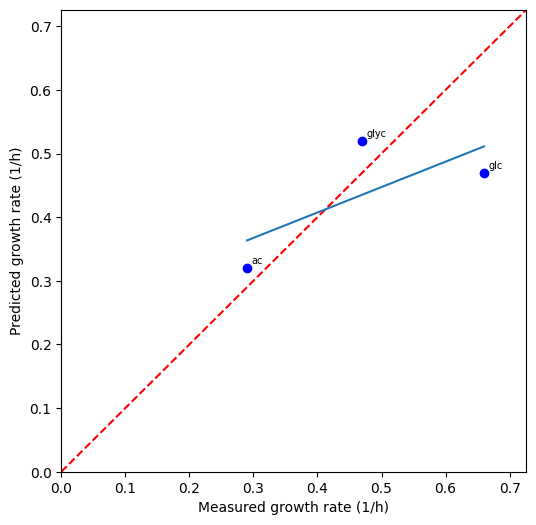

In [26]:
from ccfbapy import scatterPlot
scatterPlot([0.66, 0.47, 0.29], [0.47, 0.52, 0.32], xlbl='Measured growth rate (1/h)',
            ylbl='Predicted growth rate (1/h)', labels=['glc', 'glyc', 'ac'])

[↑ Back to contents](#contents)

<a id="utilities--remove_enzyme_layer"></a>

### remove_enzyme_layer

*`ccfbapy/cfba_moment.py`*

```python
from ccfbapy import remove_enzyme_layer
remove_enzyme_layer(model)
```

Removes the variables and constraints that an earlier call of [`cfba_moment`](#cfba_moment) or
[`ccFBA_mr`](#cfba_moment_mr) added to the solver problem of `model`, so they can be added
again. `cfba_moment` and `ccFBA_mr` call it on their copy of the model. You need it only when you
reuse the `model` they return (`res['model']`).

- variables: `g_<gene>`, `gr_<gene>_<rxn>`, `cpx_*`;
- constraints: `<rxn>`, `<rxn>_b`, `<rxn>_kcat`, `<rxn>_b_kcat`, `<rxn>_<gene>`, `Aux_*`, `mfe_<gene>`, `MW`.

Reaction variables and metabolite constraints are never removed.


[↑ Back to contents](#contents)

<a id="part-r-only-replaced-or-not-needed"></a>

# R only (replaced or not needed)

<a id="getRevFlux"></a>

## 17. getRevFlux: fluxes of the reversible model

*R help page: `man/getRevFlux.Rd`. R source: `R/sybilccFBA/R/getRevFlux.R`.*

> ℹ️ **Not needed in Python**
>
> The Python functions already return the net fluxes of the reactions of the original model
> (`rxnFlx`). For a flux vector of an [irreversible model](#mod2irrev), use
> `IrrevModel.net_flux(x)`.

<a id="getRevFlux--description"></a>

### Description

Gets the fluxes of the reversible model from the fluxes of the irreversible model.


[↑ Back to contents](#contents)

<a id="getRevFlux--usage-r"></a>

### Usage (R)

```r
getRevFlux(model, irrxns, fdirrev)
```

| Argument | Description |
|---|---|
| `model` | metabolic model of class `modelorg` |
| `irrxns` | ids of the reactions of the irreversible model |
| `fdirrev` | fluxes of the irreversible model |


[↑ Back to contents](#contents)

<a id="getRevFlux--value"></a>

### Value

A data frame with the reaction id of `model` (`rxn`), the forward (`fwd`) and backward (`bwd`)
flux. The net flux is `fwd - bwd`.


[↑ Back to contents](#contents)

<a id="getRevFlux--python-equivalent"></a>

### Python equivalent

In [27]:
import cobra
import numpy as np
import pandas as pd
from ccfbapy import getccFBA_mat, solve_ccFBA_mat

model = cobra.io.read_sbml_model('models/iAF1260.xml')
mw = pd.read_csv('data/Ecoli_MW.csv')
kcat = pd.read_csv('data/Ecoli_kcat.csv')
mat = getccFBA_mat(model, Kcat=kcat, MW=mw, RHS=0.27, medval=3600*22.6, verboseMode=0)
Res = solve_ccFBA_mat(mat, verboseMode=0)

mod2 = mat['model']
flx_ir = Res['flx_ir']                     # fluxes of the irreversible model (R: fdirrev)
net = mod2.net_flux(flx_ir)                # fwd - bwd, in the order of model.reactions
fluxes = pd.DataFrame({'rxn': mod2.rxn_id_orig,
                       'fwd': flx_ir[mod2.rev2irrev[:, 0]],
                       'bwd': np.where(mod2.react_rev, flx_ir[mod2.rev2irrev[:, 1]], 0)})
print(fluxes[fluxes['fwd'] + fluxes['bwd'] > 1e-6].head())

        rxn       fwd  bwd
9    3OAR40  0.082819  0.0
11   3OAR60  0.082819  0.0
12   3OAR80  0.082819  0.0
13  3OAS100  0.082819  0.0
15  3OAS120  0.047810  0.0


`Res['rxnFlx']` already holds `dict(zip(mod2.rxn_id_orig, net))`.


[↑ Back to contents](#contents)

<a id="getRevFlux--see-also"></a>

### See also

[`mod2irrev`](#mod2irrev), [`getccFBA_sol`](#getccFBA_sol) (`metflx`, `metflx_ir`)


[↑ Back to contents](#contents)

<a id="sysBiolAlg_ccFBA"></a>

## 18. sysBiolAlg_ccFBA: problem object of ccFBA

*R help pages: `man/sysBiolAlg_ccFBA-class.Rd` (class `sysBiolAlg_ccFBA`, aliases
`sysBiolAlg_ccFBA`, `ccFBA`) and `man/initialize-methods.Rd` (its `initialize` method). R source:
`R/sybilccFBA/R/sysBiolAlg_ccFBAClass.R`.*

> ℹ️ **Replaced in Python**
>
> There is no class. [`solve_ccFBA_mat`](#getccFBA_mat--solve_ccfba_mat) builds an optlang
> problem from the result of [`getccFBA_mat`](#getccFBA_mat) and solves it. This replaces
> `sysBiolAlg(..., algorithm="ccFBA")` followed by `optimizeProb()`.

<a id="sysBiolAlg_ccFBA--description-r"></a>

### Description (R)

The class `sysBiolAlg_ccFBA` holds an object of class `optObj`, made to meet the requirements of
the ccFBA algorithm. It extends class `sysBiolAlg` directly, and no methods are defined with it in
the signature.

Objects are created by calls of the form

```r
sysBiolAlg(model, algorithm = "ccFBA", ...)
```


<a id="sysBiolAlg_ccFBA--slots"></a>

#### Slots

| Slot | Content |
|---|---|
| `problem` | object of class `optObj` containing the problem object |
| `algorithm` | name of the algorithm |
| `nr`, `nc` | number of rows and columns of the problem |
| `fldind` | columns (variables) of the fluxes: variable `fldind[i]` is reaction `i` of the network |
| `alg_par` | named list of algorithm specific parameters |


[↑ Back to contents](#contents)

<a id="sysBiolAlg_ccFBA--initialize-method"></a>

### initialize method

```r
## S4 method for signature 'sysBiolAlg_ccFBA'
initialize(.Object, model, LHS, rlb, rub, rtype, lb, ub, obj, lpdir,
           cnames = NULL, rnames = NULL, pname = NULL, scaling = NULL,
           writeProbToFileName = NULL, ...)
```

| Argument | Description | Python (`getccFBA_mat` result `mat`) |
|---|---|---|
| `.Object` | the problem object | |
| `model` | `modelorg` (the irreversible model). The bounds of the first `react_num(model)` columns are replaced by its bounds. | `mod2` argument of `solve_ccFBA_mat` (default `mat['model']`) |
| `LHS` | constraint matrix: S matrix and ccFBA constraints | `mat['LHS']` |
| `rlb`, `rub` | bounds of the rows (constraints) | `mat['rlb']`, `mat['rub']` |
| `rtype` | row type (`E`, `U`, `L`, ...) | `mat['rtype']` |
| `lb`, `ub` | bounds of the columns (variables) | `mat['clb']`, `mat['cub']` |
| `obj` | objective coefficients | `mat['obj_cf']` |
| `lpdir` | direction, `"max"` or `"min"`. Default `"max"`. | `mat['obj_dir']` |
| `cnames` | variable names. Default: the reaction ids of `model`. | `mat['cnames']` |
| `rnames` | constraint names. Default: the metabolite ids of `model`. | `mat['rnames']` |
| `pname` | name of the problem object | |
| `scaling` | scaling of the constraint matrix (see `scaleProb`). Default: no scaling. | |
| `writeProbToFileName` | file name to write the problem in LP format | `open(f, 'w').write(Res['prob'].to_lp())` |
| `...` | passed to the `initialize` method of `sysBiolAlg`: `solver`, `method`, `solverParm` | `interface` argument of `solve_ccFBA_mat` |


[↑ Back to contents](#contents)

<a id="sysBiolAlg_ccFBA--details"></a>

### Details

The problem object is built to perform cost constrained flux balance analysis with a given model.
This is a linear programming problem:

```
max  c^T v
s.t. S v = 0
     a_i <= v_i <= b_i      for i = 1, ..., n
     + the ccFBA constraints (kcat, complexes, multi-functional enzymes, budget)
```

`S` is the stoichiometric matrix, `a_i` and `b_i` are the lower and upper bounds of flux
(variable) `i`, and `n` is the number of variables. The solution is a flux distribution that
maximizes the objective `c^T v` in the given environment, at steady state.


[↑ Back to contents](#contents)

<a id="sysBiolAlg_ccFBA--example"></a>

### Example

R:

```r
prob <- sysBiolAlg(mod2, LHS=mrMat$LHS, rlb=mrMat$rlb, rub=mrMat$rub, rtype=mrMat$rtype,
                   lb=mrMat$clb, ub=mrMat$cub, obj=mrMat$obj_cf, lpdir='max',
                   cnames=mrMat$cnames, algorithm="ccFBA", solver="glpkAPI")
sol <- optimizeProb(prob)
```

Python:

In [28]:
import cobra
import pandas as pd
from ccfbapy import getccFBA_mat, solve_ccFBA_mat

model = cobra.io.read_sbml_model('models/iAF1260.xml')
mw = pd.read_csv('data/Ecoli_MW.csv')
kcat = pd.read_csv('data/Ecoli_kcat.csv')
mrMat = getccFBA_mat(model, Kcat=kcat, MW=mw, RHS=0.27, medval=3600*22.6, verboseMode=0)
sol = solve_ccFBA_mat(mrMat)          # uses mrMat['model'] for the flux bounds
print(sol['status'], sol['obj'])
prob = sol['prob']                    # optlang problem: add constraints, change bounds, ...

Solving LP ...


optimal 0.23274316010544244


[↑ Back to contents](#contents)

<a id="sysBiolAlg_ccFBA--references"></a>

### References

Gelius-Dietrich G, Desouki AA, Fritzemeier CJ, Lercher MJ (2013). sybil – Efficient
constraint-based modelling in R. *BMC Systems Biology* 7(1): 125.

Adadi R, et al. (2012), see [`cfba_moment`](#cfba_moment--references).


[↑ Back to contents](#contents)

<a id="part-data"></a>

# Data

<a id="data"></a>

## 19. Data sets

The R package has nine data sets in `R/sybilccFBA/data/*.RData`, each with a help page in `man/`. ccFBApy
ships them as **SBML** (models) and **CSV** (tables) files, read with
[`ccfbapy.datasets`](#data--data-sets-in-the-package). The package does not read `.RData` files and does not need
R or the package `rdata`: the files were exported once from the `.RData` files (see
[How the data sets were made](#data--how-the-data-sets-were-made)).

In [29]:
from ccfbapy import datasets
iAF1260 = datasets.load_model('iAF1260')                              # R: data(iAF1260)
print(iAF1260.id, len(iAF1260.reactions), 'reactions')

Ec_iAF1260 2382 reactions


| R data set | Content | Python | File in the package (`ccfbapy/data/`) |
|---|---|---|---|
| [`iAF1260`](#data--iaf1260) | *E. coli* model | `datasets.load_model('iAF1260')` | `sybilccFBA/iAF1260.xml.gz` |
| [`iJO1366`](#data--ijo1366) | *E. coli* model | `datasets.load_model('iJO1366')` | `sybilccFBA/iJO1366.xml.gz` |
| [`iML1515`](#data--iml1515) | *E. coli* model | `datasets.load_model('iML1515')` | `sybilccFBA/iML1515.xml.gz` |
| [`iMM904`](#data--imm904) | *S. cerevisiae* model | `datasets.load_model('iMM904')` | `sybilccFBA/iMM904.xml.gz` |
| [`kcat`](#data--kcat) | *E. coli* kcat values | `datasets.load_dataset('kcat')` | `sybilccFBA/kcat.csv` |
| [`mw`](#data--mw) | *E. coli* molecular weights | `datasets.load_dataset('mw')` | `sybilccFBA/mw.csv` |
| [`mw_iML1515`](#data--mw_iml1515) | molecular weights of the iML1515 genes | `datasets.load_dataset('mw_iML1515')` | `sybilccFBA/mw_iML1515.csv` |
| [`yst_kcat`](#data--yst_kcat) | *S. cerevisiae* kcat values | `datasets.load_dataset('yst_kcat')` | `sybilccFBA/yst_kcat.csv` |
| [`yst_mw`](#data--yst_mw) | *S. cerevisiae* molecular weights | `datasets.load_dataset('yst_mw')` | `sybilccFBA/yst_mw.csv` |

<a id="data--two-versions-of-the-models"></a>

### Two versions of the models

There are two SBML versions of each model:

- `datasets.load_model(name)` (default, `source='sybilccFBA'`): **the data set of the R package**, with the ids of
  sybil, its bounds and GPR rules. The results are the same as with the R data set (e.g. the tests of the
  package: `cfba_moment_pw` on iAF1260 gives 0.508335 with both).
- `datasets.load_model(name, source='bigg')`, or `cobra.io.read_sbml_model('models/<name>.xml')` in the
  repository: the SBML models of the folder `models/`, with BiGG ids. They are another version of the models:
  with the default bounds the FBA optimum is the same, but some ids and bounds differ (e.g. upper bounds 999999
  instead of 1000, ATPM). The examples of this manual that use `models/` are written for this version.

| Model | R data set (`source='sybilccFBA'`): reactions / metabolites / genes | example ids | BiGG (`source='bigg'`, `models/*.xml`) | example ids |
|---|---|---|---|---|
| iAF1260 | 2382 / 1668 / 1261 | `R_EX_glc_e_`, `R_ATPM` | 2382 / 1668 / 1261 | `EX_glc__D_e`, `ATPM` |
| iJO1366 | 2583 / 1805 / 1367 | `EX_glc(e)`, `ATPM` | 2583 / 1805 / 1367 | `EX_glc__D_e` |
| iML1515 | 2712 / 1877 / 1516 | `EX_glc__D(e)`, `ATPM` | 2712 / 1877 / 1516 | `EX_glc__D_e` |
| iMM904 | 1577 / 1228 / 904 | `R_EX_glc_e_`, `R_ATPM` | 1577 / 1226 / 905 | `EX_glc__D_e` |

The gene counts of the *E. coli* models include the spontaneous pseudo gene `s0001`. The kcat data set `kcat`
(ids of the R iAF1260) matches 508 reactions of the R iAF1260 and 501 of the BiGG version. With glucose and
oxygen open, `cfba_moment_pw` gives 0.508335 with the R version (as the MATLAB MOMENT model, 0.508309) and
0.511998 with the BiGG version.


[↑ Back to contents](#contents)

<a id="data--iaf1260"></a>

### iAF1260

*Escherichia coli* metabolic model iAF1260 (`man/iAF1260.Rd`).

A genome scale metabolic network of *E. coli*: 2077 internal reactions, 304 exchange reactions and
a biomass objective function.

- **Usage** R: `data(iAF1260)`. Python: `datasets.load_model('iAF1260')`. BiGG version:
  `datasets.load_model('iAF1260', source='bigg')` or `cobra.io.read_sbml_model('models/iAF1260.xml')`.
- **Format** R: an object of class `modelorg`. Python: `cobra.Model`.
- **Reference** Feist AM, Henry CS, Reed JL, Krummenacker M, Joyce AR, Karp PD, Broadbelt LJ,
  Hatzimanikatis V, Palsson BØ (2007). A genome-scale metabolic reconstruction for *Escherichia
  coli* K-12 MG1655 that accounts for 1260 ORFs and thermodynamic information. *Mol Syst Biol* 3: 121.


[↑ Back to contents](#contents)

<a id="data--ijo1366"></a>

### iJO1366

*Escherichia coli* metabolic model iJO1366 (`man/iJO1366.Rd`).

A genome scale metabolic network of *E. coli*: 2253 internal reactions, 330 exchange reactions and
a biomass objective function.

- **Usage** R: `data(iJO1366)`. Python: `datasets.load_model('iJO1366')`. BiGG version:
  `datasets.load_model('iJO1366', source='bigg')` or `cobra.io.read_sbml_model('models/iJO1366.xml')`.
- **Format** R: `modelorg`. Python: `cobra.Model`.
- **Reference** Orth JD, Conrad TM, Na J, Lerman JA, Nam H, Feist AM, Palsson BØ (2011). A
  comprehensive genome-scale reconstruction of *Escherichia coli* metabolism—2011. *Mol Syst Biol* 7(1).


[↑ Back to contents](#contents)

<a id="data--iml1515"></a>

### iML1515

*Escherichia coli* metabolic model iML1515 (`man/iML1515.Rd`).

A genome scale metabolic network of *E. coli*: 2381 internal reactions, 331 exchange reactions and
a biomass objective function. It has 1515 genes. Used in the example of
[`simulate_EColi`](#simulate_EColi).

- **Usage** R: `data(iML1515)`. Python: `datasets.load_model('iML1515')`. BiGG version:
  `datasets.load_model('iML1515', source='bigg')` or `cobra.io.read_sbml_model('models/iML1515.xml')`.
- **Format** R: `modelorg`. Python: `cobra.Model`.
- **Reference** Monk JM, et al. (2017). iML1515, a knowledgebase that computes *Escherichia coli*
  traits. *Nature Biotechnology* 35(10): 904.


[↑ Back to contents](#contents)

<a id="data--imm904"></a>

### iMM904

*Saccharomyces cerevisiae* metabolic model (`man/iMM904.Rd`).

A genome scale metabolic network of *S. cerevisiae*: 1412 internal reactions, 164 exchange
reactions and a biomass objective function.

- **Usage** R: `data(iMM904)`. Python: `datasets.load_model('iMM904')`. BiGG version:
  `datasets.load_model('iMM904', source='bigg')` or `cobra.io.read_sbml_model('models/iMM904.xml')`.
- **Format** R: `modelorg`. Python: `cobra.Model`.
- **Reference** Mo ML, Palsson BØ, Herrgård MJ (2009). Connecting extracellular metabolomic
  measurements to intracellular flux states in yeast. *BMC Syst Biol* 3: 37.


[↑ Back to contents](#contents)

<a id="data--kcat"></a>

### kcat

*Escherichia coli* kcat values used in the MOMENT method (`man/kcat.Rd`).

A list of kcat values used in MOMENT, in 1/s.

- **Usage** R: `data(kcat)`. Python: `datasets.load_dataset('kcat')`. The same values are in
  `data/Ecoli_kcat.csv` (`datasets.load_kcat()`).
- **Format** a data frame with three columns and 508 rows: `rxn_id` (iAF1260 reaction id with the
  `R_` prefix, e.g. `R_ASPTA`), `val` (kcat, 1/s), `dirxn` (`1`: 452 rows, `-1`: 56 rows). It can be
  given as `Kcat` to all the functions (see [Kcat](#conventions--kinetic-data-kcat)).
- **Reference** Adadi R, Volkmer B, Milo R, Heinemann M, Shlomi T (2012). Prediction of microbial
  growth rate versus biomass yield by a metabolic network with kinetic parameters. *PLoS Comput
  Biol* 8(7). doi:10.1371/journal.pcbi.1002575


[↑ Back to contents](#contents)

<a id="data--mw"></a>

### mw

*Escherichia coli* molecular weights used in the MOMENT method (`man/mw.Rd`).

- **Usage** R: `data(mw)`. Python: `datasets.load_dataset('mw')`.
- **Format** a data frame with two columns and 1260 rows: `Synonym` (b-number) and `mw`. The help
  page gives the unit as g/mol, but the values are in g/mmol (kDa), e.g. b0002: 89.12 (see
  [units](#conventions--units)). `s0001` is not included.
- `data/Ecoli_MW.csv` (`datasets.load_mw()`, columns `Synonym`, `mw`) has 1548 genes: the 1260 genes of `mw`, and 288
  more. For 7 genes the values differ by up to 2%.
- **Reference** Adadi et al. (2012), see [kcat](#data--kcat).


[↑ Back to contents](#contents)

<a id="data--mw_iml1515"></a>

### mw_iML1515

Molecular weights of the *E. coli* metabolic genes of iML1515, used in MOMENT/ccFBA (`man/mw_iML1515.Rd`).

Calculated with [`calc_MW`](#calc_MW) from the *E. coli* genome sequence available at NCBI.

- **Usage** R: `data(mw_iML1515)`. Python: `datasets.load_dataset('mw_iML1515')`.
- **Format** a data frame with two columns and 1515 rows: `Synonym` and `mw` (g/mmol). The
  example of [`simulate_EColi`](#simulate_EColi) adds `s0001` with MW 0.001 and
  renames the first column to `gene`.
- **Reference** Adadi et al. (2012), see [kcat](#data--kcat).


[↑ Back to contents](#contents)

<a id="data--yst_kcat"></a>

### yst_kcat

*Saccharomyces cerevisiae* kcat values used in the MOMENT method (`man/yst_kcat.Rd`).

A list of kcat values for yeast, in 1/s.

- **Usage** R: `data(yst_kcat)`. Python: `datasets.load_dataset('yst_kcat')`. The same values are in
  `data/yeast_imm_kcat.csv` (`datasets.load_yeast_kcat()`).

In [30]:
from ccfbapy import datasets
yst_kcat = datasets.load_dataset('yst_kcat')
print(yst_kcat.head())

   rxn_id      val  dirxn
0      13  2.10309      1
1      14  0.22000      1
2      15  6.11161      1
3      16  6.11161      1
4      17  1.53000      1


- **Format** the help page says "a data frame with three columns". In R it is a numeric matrix with
  938 rows and the columns `rxn_id`, `val`, `dirxn` (a DataFrame in Python). `rxn_id` is a number (1–469, each with
  `dirxn` 1 and −1), not a reaction id. The help page does not say which reactions the numbers
  refer to, so check this before you use the values with `iMM904`.
- **References** Richter C (2011). *Kosten und Effizienz von Enzymen als zusätzliche Bedingung für
  die Flussverteilung in metabolischen Netzwerken.* Diploma thesis, Humboldt University Berlin.
  Adadi et al. (2012), see [kcat](#data--kcat).


[↑ Back to contents](#contents)

<a id="data--yst_mw"></a>

### yst_mw

*Saccharomyces cerevisiae* molecular weights used in the MOMENT method (`man/yst_mw.Rd`).

Calculated with [`calc_MW`](#calc_MW) from the yeast genome sequence available at NCBI
(*S. cerevisiae* S288c).

- **Usage** R: `data(yst_mw)`. Python: `datasets.load_dataset('yst_mw')`. The same values are in
  `data/yeast_mw.csv` (`datasets.load_yeast_mw()`).
- **Format** a data frame with 5899 rows and the columns `gene` (systematic name, e.g. `YAL005C`),
  `mw` (g/mmol) and `LENGTH` (number of amino acids).
- **Reference** Adadi et al. (2012), see [kcat](#data--kcat).


[↑ Back to contents](#contents)

<a id="data--data-sets-in-the-package"></a>

### Data sets in the package

The module `ccfbapy.datasets` gives the data of the package, so they can be used without a copy of
the repository. Only SBML and CSV files are read (cobra and pandas).

| Function | Returns |
|---|---|
| `load_model(name, source='sybilccFBA')` | a model as `cobra.Model`: `iAF1260`, `iJO1366`, `iML1515`, `iMM904`. `source='sybilccFBA'`: the R data set (sybil ids); `source='bigg'`: the model of `models/` (BiGG ids), see [Two versions of the models](#data--two-versions-of-the-models) |
| `load_dataset(name)` | an R data set: the models (as `load_model(name)`) and the tables `kcat`, `mw`, `mw_iML1515`, `yst_kcat`, `yst_mw` (DataFrame) |
| `list_datasets()` | the names of the data sets |
| `model_path(name, source='sybilccFBA')` | the path of the SBML file (gzip) of a model |
| `load_kcat()`, `load_mw()` | *E. coli* kcat values (1/s) and molecular weights (g/mmol): `data/Ecoli_kcat.csv`, `data/Ecoli_MW.csv` |
| `load_yeast_kcat()`, `load_yeast_mw()` | the same for *S. cerevisiae*: `data/yeast_imm_kcat.csv`, `data/yeast_mw.csv` |
| `load_cpx_stoich()` | protein complex stoichiometry, `cpx_stoich_me.csv` (for `cpx_stoich`) |
| `load_kcat_list(model=None, column='kcat_max')` | `allKcats_upd34_dd_h.csv` as a Kcat table (`rxn_id`, `val`, `dirxn`, `src`), as in the example of `simulate_EColi`; only the reactions of `model` when it is given |
| `extdata_path(fname=None)` | the folder of the example files of sybilccFBA (`inst/extdata`, see below), or the path of one of them. [`calc_MW`](#calc_MW) and [`readmodel`](#readmodel) use these files by default. |
| `data_path(fname=None)` | the data folder of the package |

In [31]:
from ccfbapy import datasets

model = datasets.load_model('iML1515')
kcat = datasets.load_kcat_list(model)            # kcat_max, reactions of iML1515
cpx_stoich = datasets.load_cpx_stoich()
print(model.id, len(model.reactions), kcat.shape, cpx_stoich.shape)
print(datasets.load_kcat().head(3))
bigg = datasets.load_model('iML1515', source='bigg')
print(bigg.reactions.get_by_id('EX_glc__D_e').name)

iML1515 2712 (651, 4) (1281, 7)
    rxn_id        val  dirxn
0  R_AOXSr   0.000916      1
1  R_ASPTA  82.471429      1
2   R_BTS4   6.950007      1


D-Glucose exchange


[↑ Back to contents](#contents)

<a id="data--how-the-data-sets-were-made"></a>

### How the data sets were made

The development tool `tools/make_package_data.py` of the repository prepares `ccfbapy/data`. It copies the CSV
tables of `data/` and the files of `R/sybilccFBA/inst/extdata`, compresses the SBML models of `models/`
(`bigg/*.xml.gz`), and exports the data sets of the R package to `sybilccFBA/`: the models with
`cobra.io.write_sbml_model` (gzip), the tables as CSV. Only this export reads `.RData` files: it needs
`pip install rdata` and `tools/sybil2cobra.py`, not the package.

Each export is read again and compared with the R data set:

- models: reaction, metabolite and gene ids and their order, bounds, stoichiometry, GPR rules, objective,
  names and formulas, and the FBA optimum;
- tables: all values, exactly (the package reads the CSV files with `float_precision='round_trip'`).

Three things SBML cannot store as in R:

- in the R data sets of iAF1260 and iMM904 the metabolites have no compartment (`met_comp` is NA, ids such as
  `M_glc_D_c[NA]`). SBML needs one: it is taken from the id (the letter before `[`, e.g. `c`); the ids are kept;
- SBML writes the GPR rules without redundant parentheses (`(A and B) and C` becomes `A and B and C`, the
  same rule);
- a missing metabolite charge (iAF1260) is read as 0.

None of them changes the results.


[↑ Back to contents](#contents)

<a id="data--other-data-files"></a>

### Other data files

Files in `R/sybilccFBA/inst/extdata` (R: `system.file("extdata", ..., package="sybilccFBA")`). They are also in
the package: `datasets.extdata_path(fname)`.

| File | Content | Used by |
|---|---|---|
| `allKcats_upd34_dd_h.csv` | *E. coli* kcat values from several sources: `ijo_id` (reaction id without `R_`), `iaf_id`, `dirxn`, `src`, `kcat_max`, ... | examples of `simulate_EColi`, package help page |
| `cpx_stoich_me.csv` | protein complex stoichiometry: `genes`, `stoich`, `Enzyme.ID`, `Gene.composition`, ... | `cpx_stoich` argument |
| `Ec_core_genedef.csv`, `Ec_iAF1260_genedef.csv`, `iJO1366_genedef.csv` | gene definitions of *E. coli* models: gene, molecular weight (`mw`/`MW`, g/mmol), gene name, product, ... | examples of the R help pages (`Ec_core`), gene names in `test_simulate_EColi.ipynb` |
| `yst_genedef.csv` | yeast gene definitions (`mw` in g/mol) | |
| `aa.txt`, `test2.ptt`, `NC_000913.faa`, `ALL_PTT.TSV` | amino acid weights, protein tables (*E. coli* `test2.ptt`, yeast `ALL_PTT.TSV`) and *E. coli* protein sequences | [`calc_MW`](#calc_MW) |
| `mat.csv`, `mets.csv`, `rxns.csv`, `rbnds.csv`, `cbnds.csv` | MOMENT model exported from MATLAB (iAF1260) | [`readmodel`](#readmodel), read with `read_moment_files()` |
| `iJO1366_mod2_mppv.csv`, `iJO_M_prot_pool.csv` | protein pool values of the iJO1366 reactions (`MppVal`) | |

`R/OverExpr/kcat2` is the kcat file of `test_simGeneOverExpr.R` (columns `rxn_id`, `val`,
`dirxn`, tab separated, no header).


[↑ Back to contents](#contents)

<a id="part-differences"></a>

# Differences

<a id="differences"></a>

## 20. Differences from R and known issues

A summary of the notes on the function pages.

<a id="differences--general"></a>

### General

| R (sybilccFBA) | Python |
|---|---|
| sybil `modelorg` | `cobra.Model` |
| `mod2 = mod2irrev(model)` | [`mod2irrev(model, rev=None)`](#mod2irrev) (`IrrevModel`). `cfba_moment` and `ccFBA_mr` have no `mod2` and use the bounds of the cobra model. |
| `uppbnd(mod2)[...] <- x` | `mod2.uppbnd[mod2.react_id.index(...)] = x` |
| `sysBiolAlg(..., algorithm="ccFBA")` + `optimizeProb()` | [`solve_ccFBA_mat(mat)`](#getccFBA_mat--solve_ccfba_mat) |
| `solver = "glpkAPI"` / `"cplexAPI"` | argument accepted but not used; set the solver in cobra/optlang |
| `verboseMode = 3` writes the LP file | not available; use `prob.to_lp()` |
| results: sybil `optsol` (`sol$fluxes`), `geneCol` | `dict` with `obj`, `status`, `rxnFlx`, `geneConc`, `prob` |
| 1-based indices | 0-based indices |
| `getRevFlux()` | `rxnFlx` in the results, `IrrevModel.net_flux()` |
| `data(iAF1260)`, `data(kcat)`, ... | `datasets.load_model('iAF1260')`, `datasets.load_dataset('kcat')`, ...: the data sets as SBML and CSV files (no `.RData`) |


[↑ Back to contents](#contents)

<a id="differences--per-function"></a>

### Per function

- [`cfba_moment`](#cfba_moment): no `mod2`, `runFVA`, `fvaRxn`. `objVal` is
  ignored and `RHS=None` gives no budget constraint, not the minimum budget.
- [`cfba_moment_mr` → `ccFBA_mr`](#cfba_moment_mr): also no `C_mu_coef`. The
  multi-functional enzyme constraints are `sum <= g` (R: `=`). Returns fewer results (no
  `rxnMC`, `rxnGeneMC`, `actual_C`, ...).
- [`getGpr1iso`](#getGpr1iso): arguments `(model, MW, cpx_stoich=None)`; R:
  `(model, cpx_stoich, MW)`.
- [`getccFBA_mat`](#getccFBA_mat): with `RHS=None`, the constraint on the objective
  has an effect (in R it is written to a wrong row). Reactions that are not selected get no enzyme
  column.
- [`getccFBA_sol`](#getccFBA_sol), [`simulate_EColi`](#simulate_EColi):
  the enzyme concentration of a reaction is `x[exprCol] / r1gstoich`. R divides by the
  stoichiometry of each gene.
- [`simGeneOverExpr`](#simGeneOverExpr): when the gene has no concentration
  variable, the budget is reduced by `y_pct` (R stops with an error).
- [`calc_MW`](#calc_MW): returns numbers (R: text). A `.faa` file with a single protein
  is handled. `nchrm` defaults to the number of files.
- [`readmodel`](#readmodel): the size of the problem is taken from the inputs (fixed in R).
  The budget `C` can be changed. The LP file is only written when `lp_fname` is given. Returns a
  `dict` (R: the vector of column values, `res['x']`). `read_moment_files` reads `mat.csv` without
  a header, so the first entry is not lost as with `read.table(header=T)`.
- [`addGlcTrns`](#addGlcTrns): completed. The R function cannot run because the
  transporter columns are never added. Python adds them (`trns_<t>`, bound `trns_ub`) and has options
  for the reaction, `Si`, the transporters and existing variables (`trnsCol`).
- [`cfba_moment_pw`](#cfba_moment_pw): built as a matrix and solved with `solve_ccFBA_mat`.
  `s0001` is removed from all OR rules. Nested rules are expanded. It works without `RHS`/`objVal`
  (no budget). The option `pairwise=False` writes one row per rule.
- All the functions of the R package are ported, except the class `sysBiolAlg_ccFBA` (replaced by
  `solve_ccFBA_mat`) and `getRevFlux` (not needed).


[↑ Back to contents](#contents)

<a id="differences--known-issues"></a>

### Known issues

- `ccFBA_mr` with `selected_rxns`: the problem is solved, but collecting `geneConc` fails with a
  `KeyError` for the genes that are not in any selected reaction.
- `cfba_moment` and `ccFBA_mr` read the kcat value from the **second column** of `Kcat` and only
  match `rxn_id` with the `R_` prefix. A table without the prefix (e.g. from
  `allKcats_upd34_dd_h.csv`) gives `medval` for every reaction, with no warning. See
  [Kcat](#conventions--kinetic-data-kcat).
- `cfba_moment` and `ccFBA_mr`: the pseudo gene `s0001` gets a concentration variable with no
  cost, so reactions with rules like `b0875 or s0001` are not limited in practice. R removes
  `s0001` from these rules (see [conventions](#conventions--spontaneous-reactions-s0001)).
- `simulate_EColi(atpmz=True)` only finds a reaction with the id `ATPM` (not `R_ATPM` of the
  `iAF1260`/`iMM904` data sets).
- `test_moment.ipynb` and `test_ccFBA_mr.ipynb` use Windows paths with lower case file names
  (`data\ecoli_kcat.csv`). The files are `data/Ecoli_kcat.csv` and `data/Ecoli_MW.csv`, which
  matters on case sensitive file systems (Linux).


[↑ Back to contents](#contents)

<a id="differences--errors-in-the-r-help-pages"></a>

### Errors in the R help pages

These are not repeated in the pages here:

- The unit of `MW` is given as g/mol; the values are in g/mmol (kDa).
- `getccFBA_sol.Rd` has the title and description of `getccFBA_mat`.
- `yst_kcat.Rd` says "a data frame"; the data set is a numeric matrix.
- `sybilccFBA-package.Rd` gives version 0.0.1 (2013); the package is version 3.0.2.
- The example of `addGlcTrns.Rd` is the body of the function, and the R function cannot run (see
  [addGlcTrns](#addGlcTrns)).
- The example of `cfba_moment_pw.Rd` calls `cfba_moment`, not `cfba_moment_pw`.


[↑ Back to contents](#contents)